<center><h1>Kalawadia_Krish_HW4</h1></center>
<br>
<br>

Name: Krish Kalawadia
<br>
Github Username: KK10-USC
<br>
USC ID: 4532974788

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import re


Get the AReM Data Set

In [2]:
my_folder = Path("HW_3_Data")
time_series_cols = ["avg_rss12","var_rss12","avg_rss13","var_rss13","vg_rss23","ar_rss23"]

my_files = list(my_folder.rglob("dataset*.csv"))
print(len(my_files))
files_frames = []

for p in my_files:
    new_rows = []
    for l in p.read_text().splitlines():
        if l.strip() and not l.startswith("#"):
            new_rows.append(l.replace(","," ").split())
    temp_df = (pd.DataFrame(new_rows).astype(float))
    temp_df["label"] = p.parent.name
    temp_df["sequence"] = p.name
    files_frames.append(temp_df)

my_df = pd.concat(files_frames,ignore_index=True)

print(my_df)
    


88
              0      1     2      3     4      5     6     label      sequence
0           0.0  39.25  0.43  22.75  0.43  33.75  1.30  bending1  dataset1.csv
1         250.0  39.25  0.43  23.00  0.00  33.00  0.00  bending1  dataset1.csv
2         500.0  39.25  0.43  23.25  0.43  33.00  0.00  bending1  dataset1.csv
3         750.0  39.50  0.50  23.00  0.71  33.00  0.00  bending1  dataset1.csv
4        1000.0  39.50  0.50  24.00  0.00  33.00  0.00  bending1  dataset1.csv
...         ...    ...   ...    ...   ...    ...   ...       ...           ...
42234  118750.0  31.50  1.66  12.50  3.20  14.25  4.44   walking  dataset9.csv
42235  119000.0  27.33  1.25  11.33  0.94  20.00  4.00   walking  dataset9.csv
42236  119250.0  37.80  7.68  14.20  2.48  17.25  0.83   walking  dataset9.csv
42237  119500.0  33.75  1.30  15.75  5.21  16.50  2.69   walking  dataset9.csv
42238  119750.0  32.67  3.09  18.67  0.47  14.00  3.16   walking  dataset9.csv

[42239 rows x 9 columns]


### (b) Splitting Data

In [3]:
bending_folder = my_df["label"].str.startswith("bending")

bending_testData = my_df["sequence"].isin(["dataset1.csv","dataset2.csv"])
other_testData = my_df["sequence"].isin(["dataset1.csv","dataset2.csv","dataset3.csv"])

my_df["test_splitting"] = (bending_folder & bending_testData) | (~bending_folder & other_testData)

training_data = my_df[~my_df["test_splitting"]]
testing_data = my_df[my_df["test_splitting"]]


### (c) Feature Extraction

In [4]:
cols = [1,2,3,4,5,6]

feature_ext = my_df.groupby(["sequence","label"])[cols].agg(["min","max","mean","median",  lambda x: x.quantile(0.25),lambda x: x.quantile(0.75)])

statistics = ["min","max","mean","median","Q1","Q3"]

new_col_names = []
for c in cols:
    for s in statistics:
        new_col_names.append(f"{c}_{s}")

feature_ext.columns = new_col_names
feature_ext = feature_ext.reset_index()
print(feature_ext.columns.to_list())

['sequence', 'label', '1_min', '1_max', '1_mean', '1_median', '1_Q1', '1_Q3', '2_min', '2_max', '2_mean', '2_median', '2_Q1', '2_Q3', '3_min', '3_max', '3_mean', '3_median', '3_Q1', '3_Q3', '4_min', '4_max', '4_mean', '4_median', '4_Q1', '4_Q3', '5_min', '5_max', '5_mean', '5_median', '5_Q1', '5_Q3', '6_min', '6_max', '6_mean', '6_median', '6_Q1', '6_Q3']


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

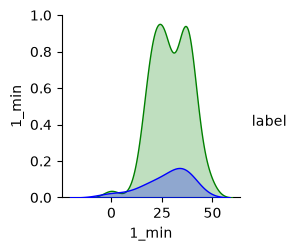

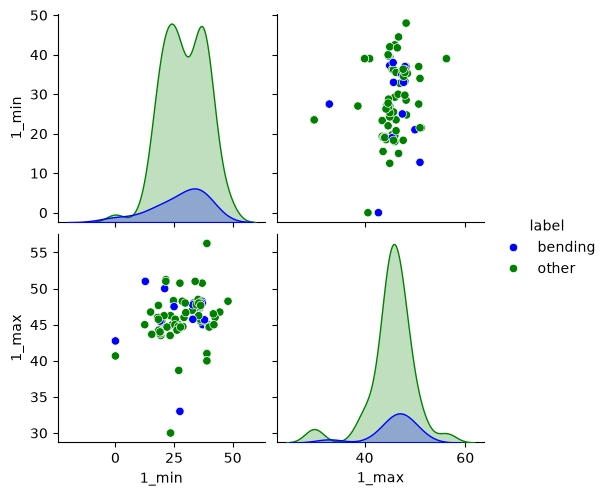

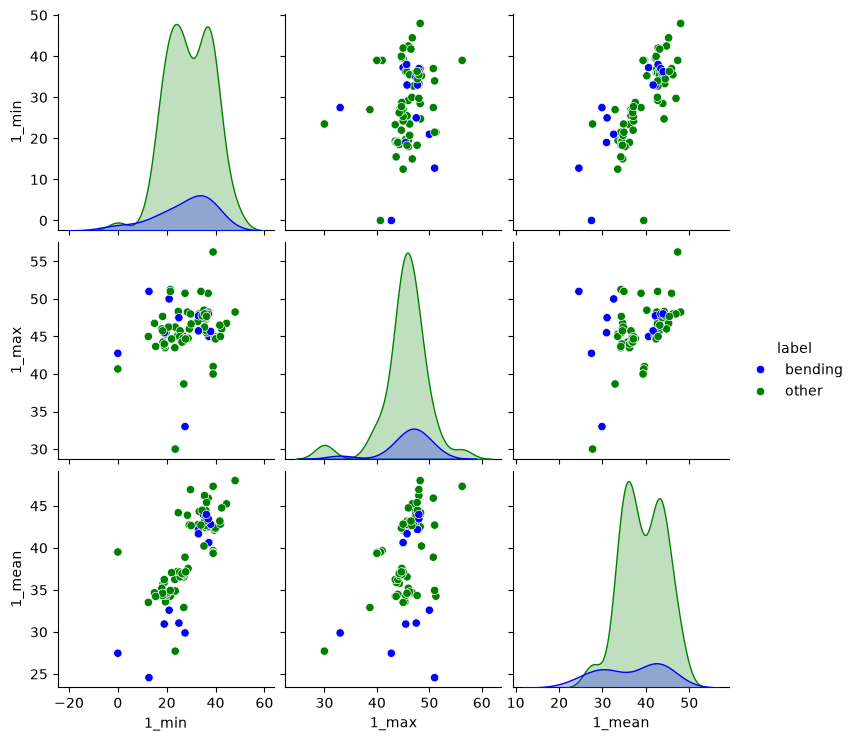

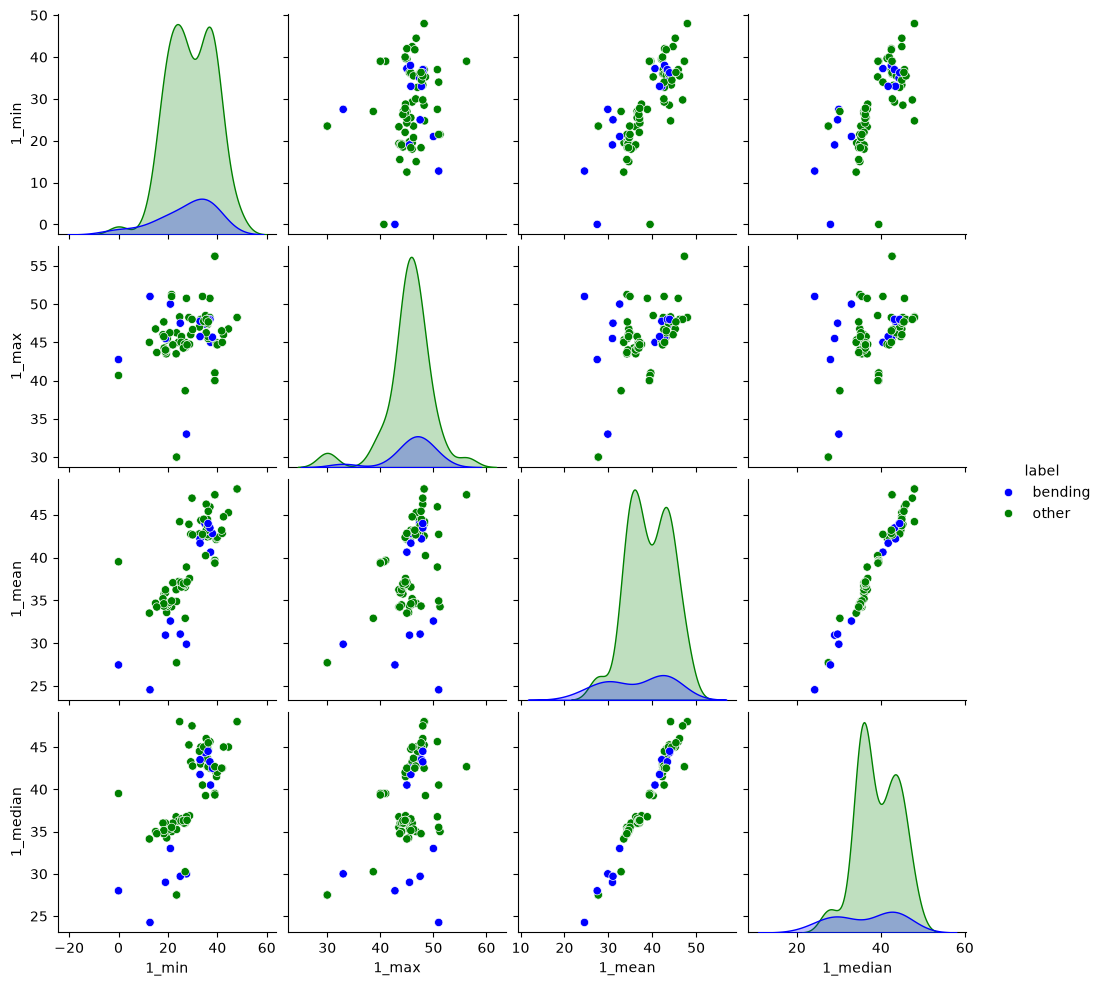

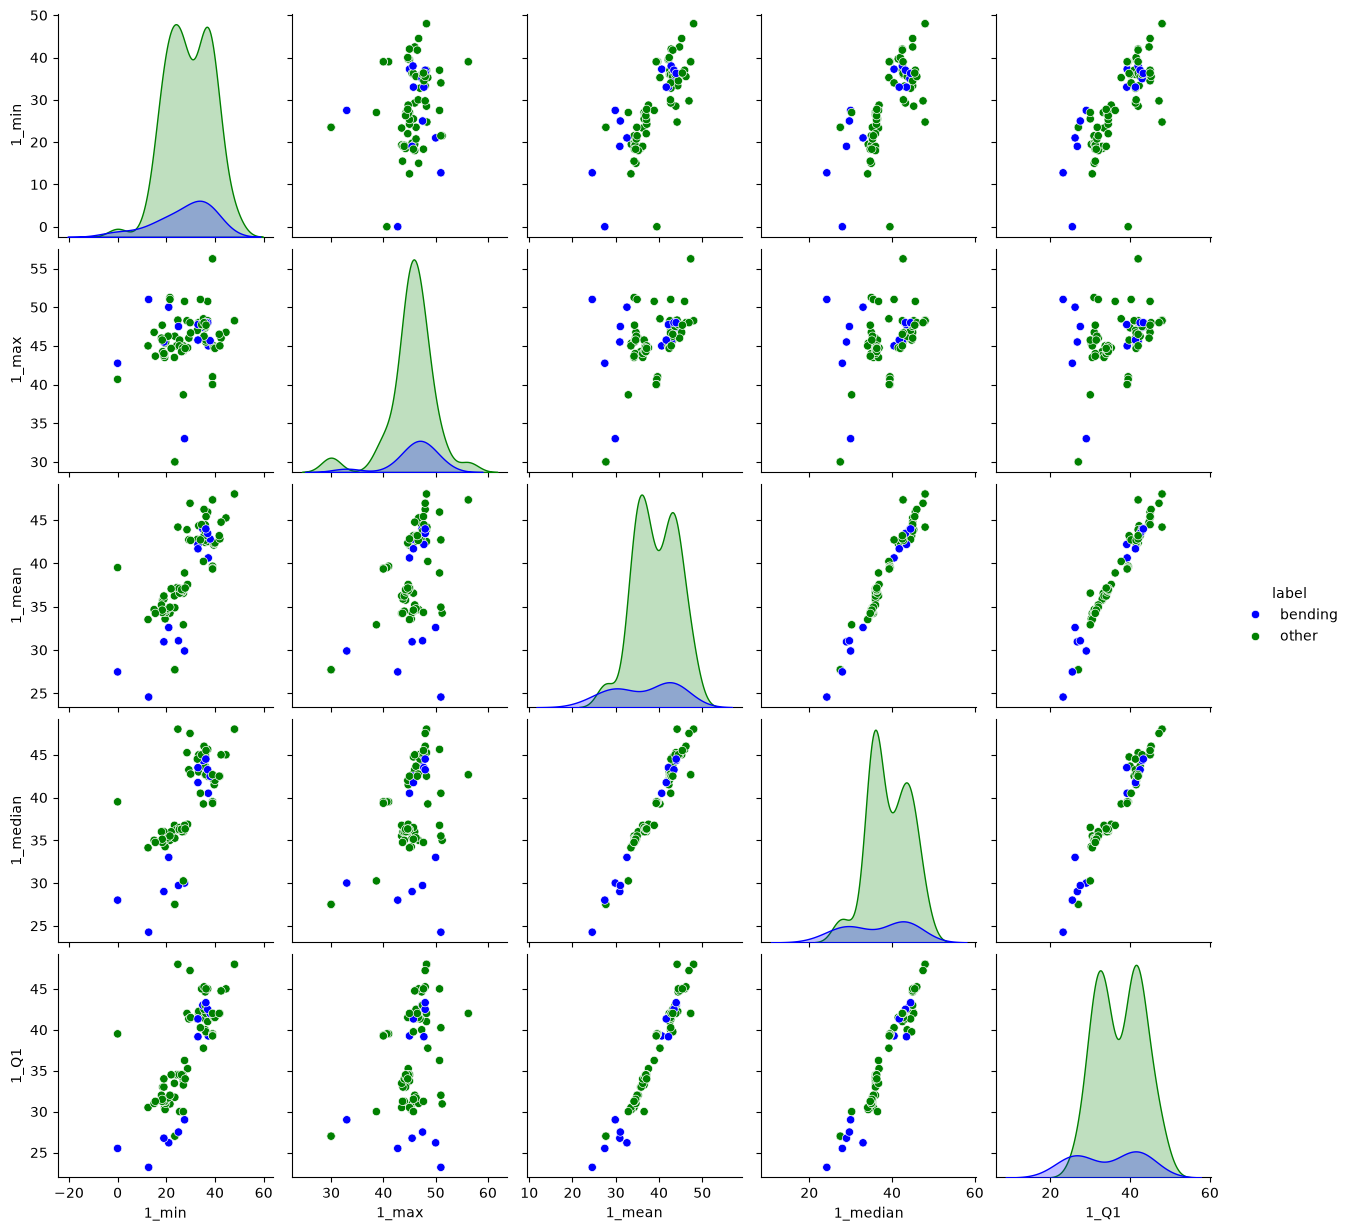

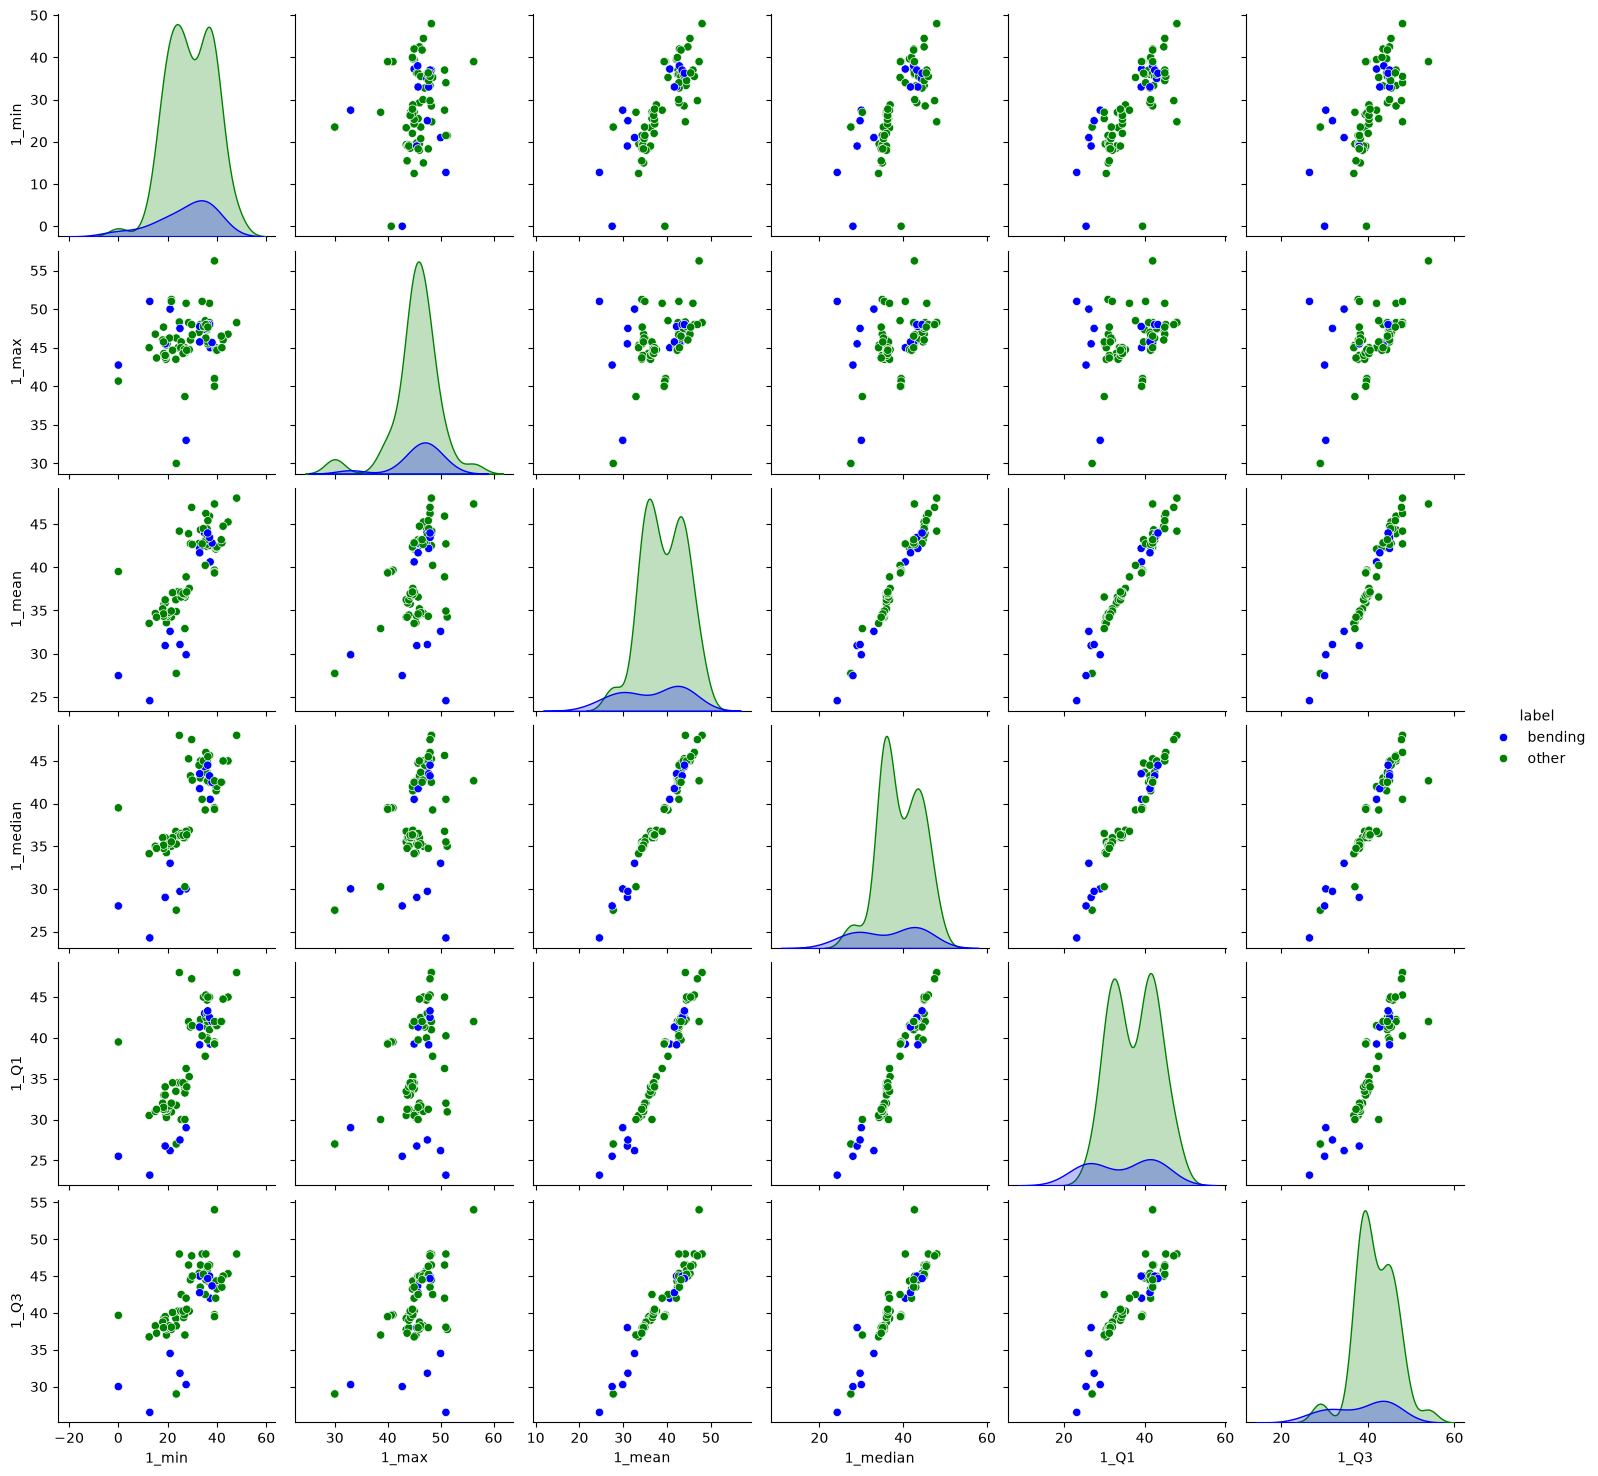

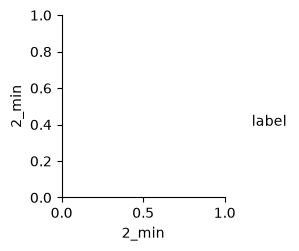

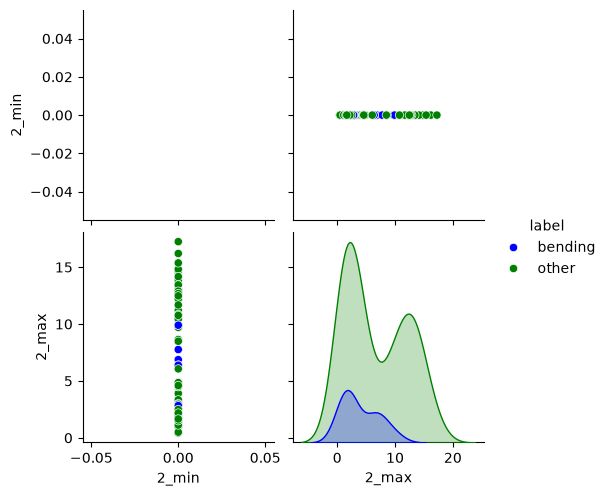

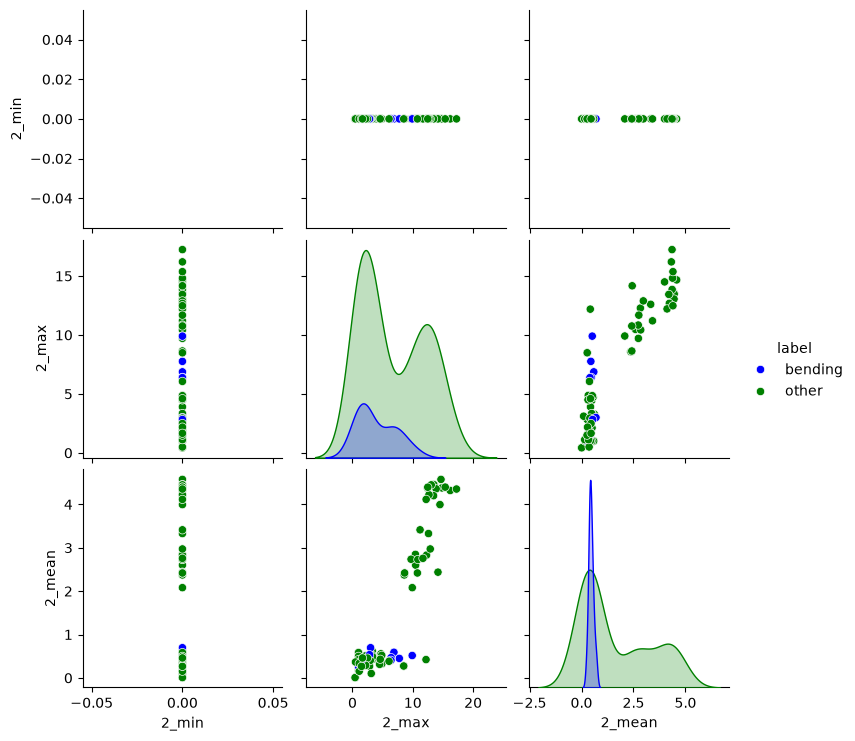

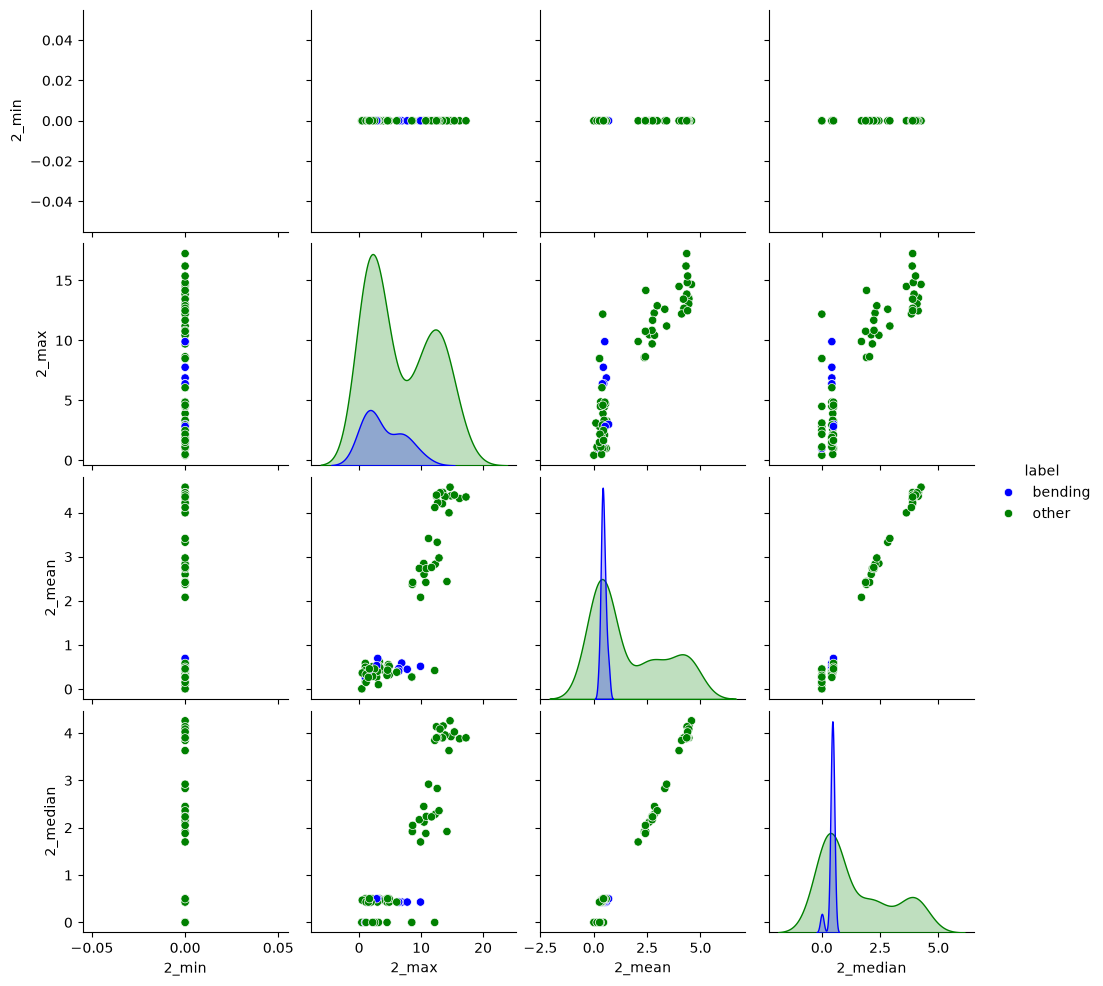

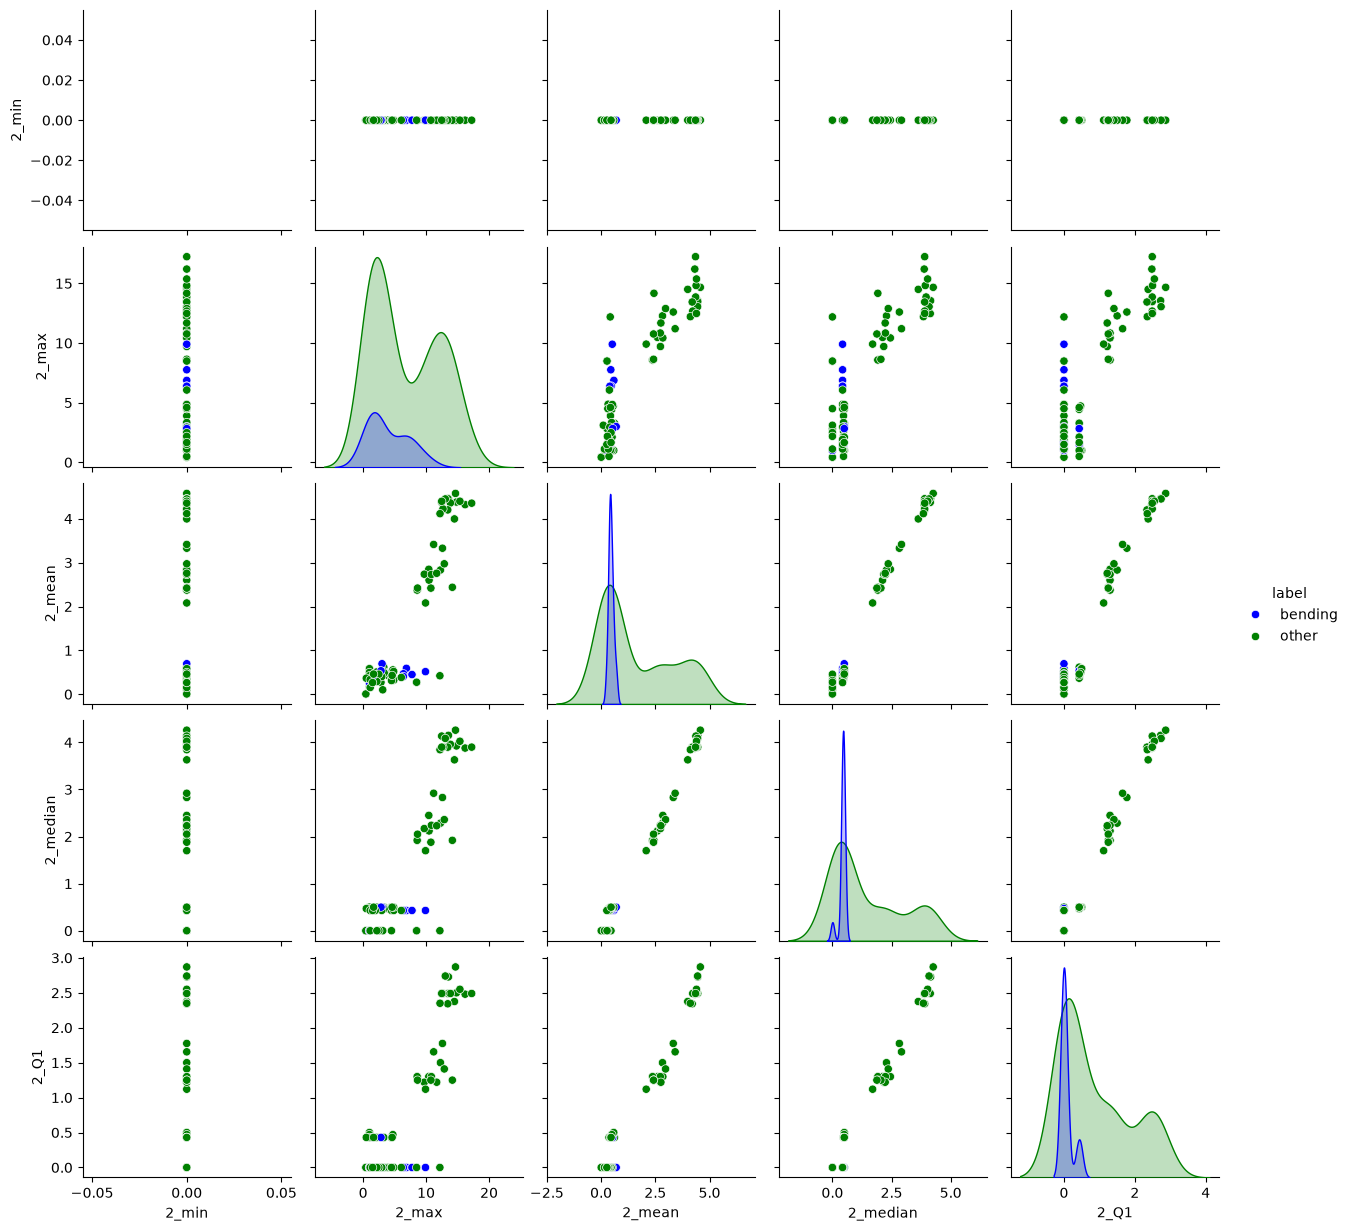

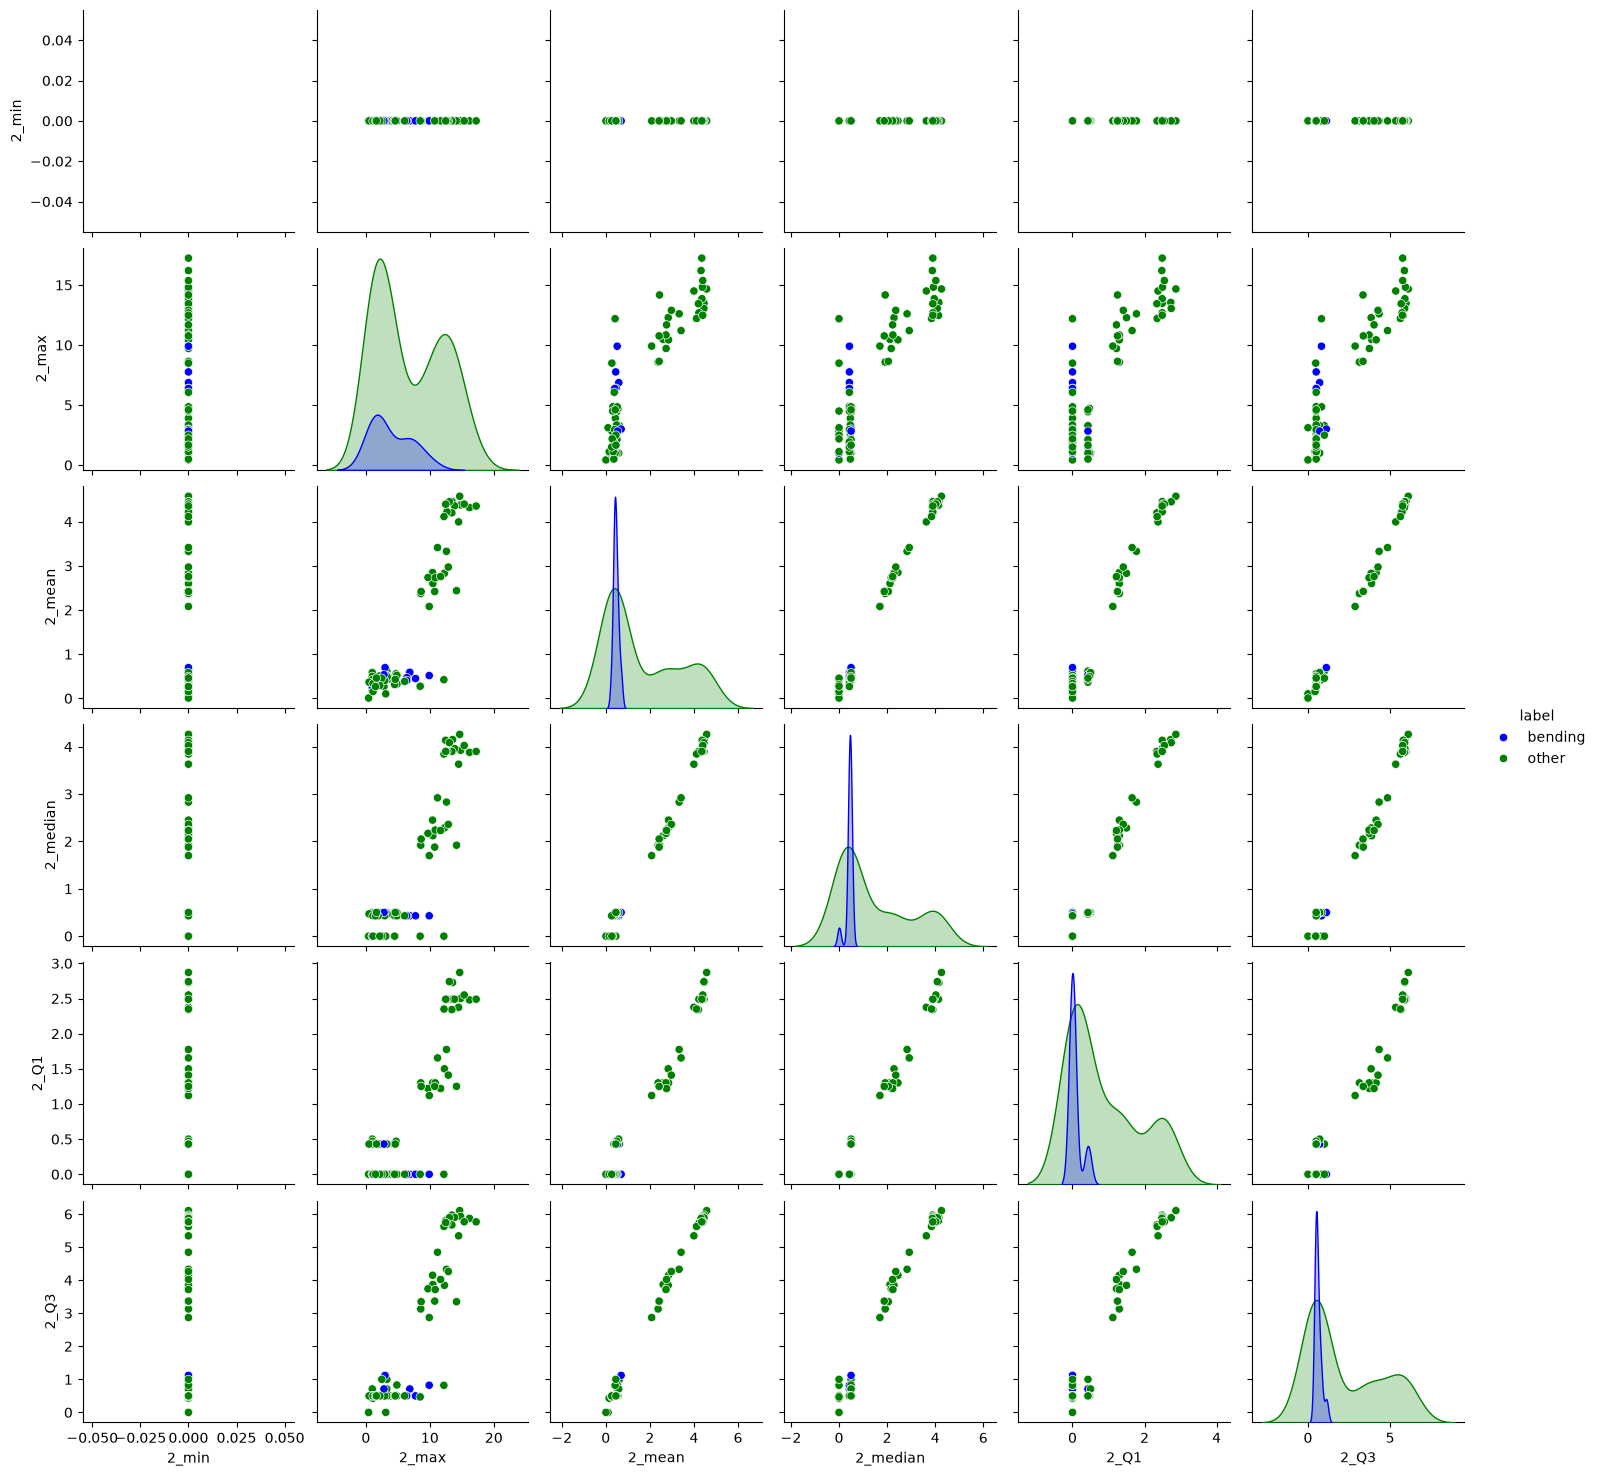

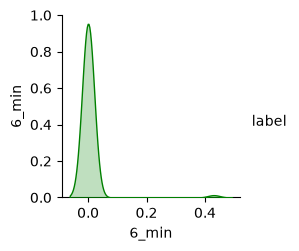

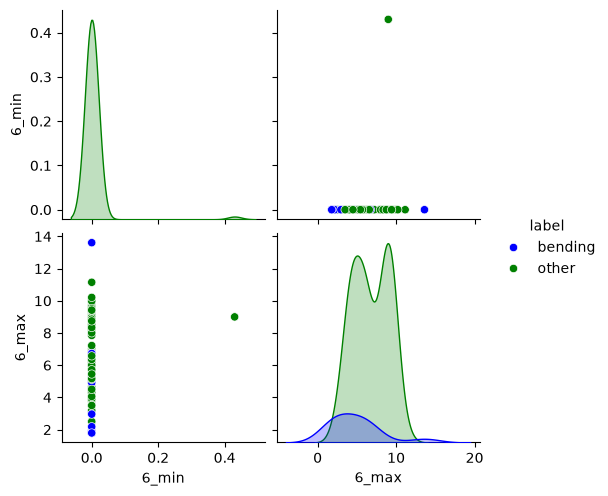

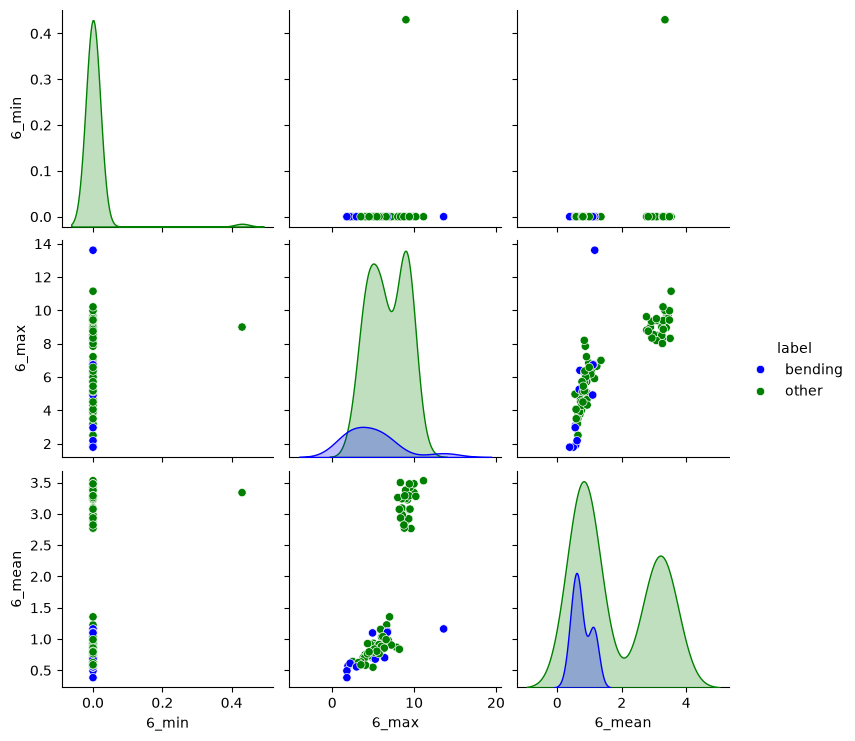

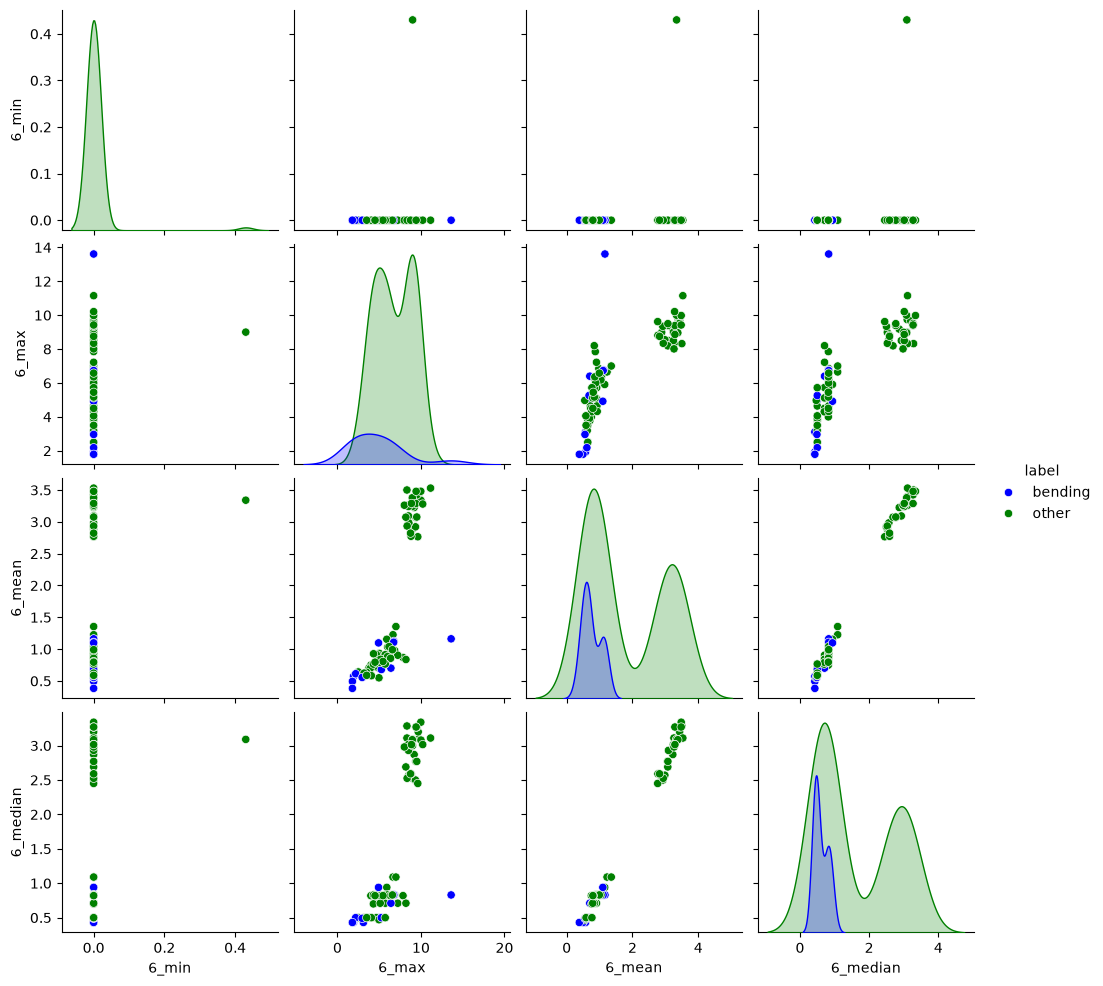

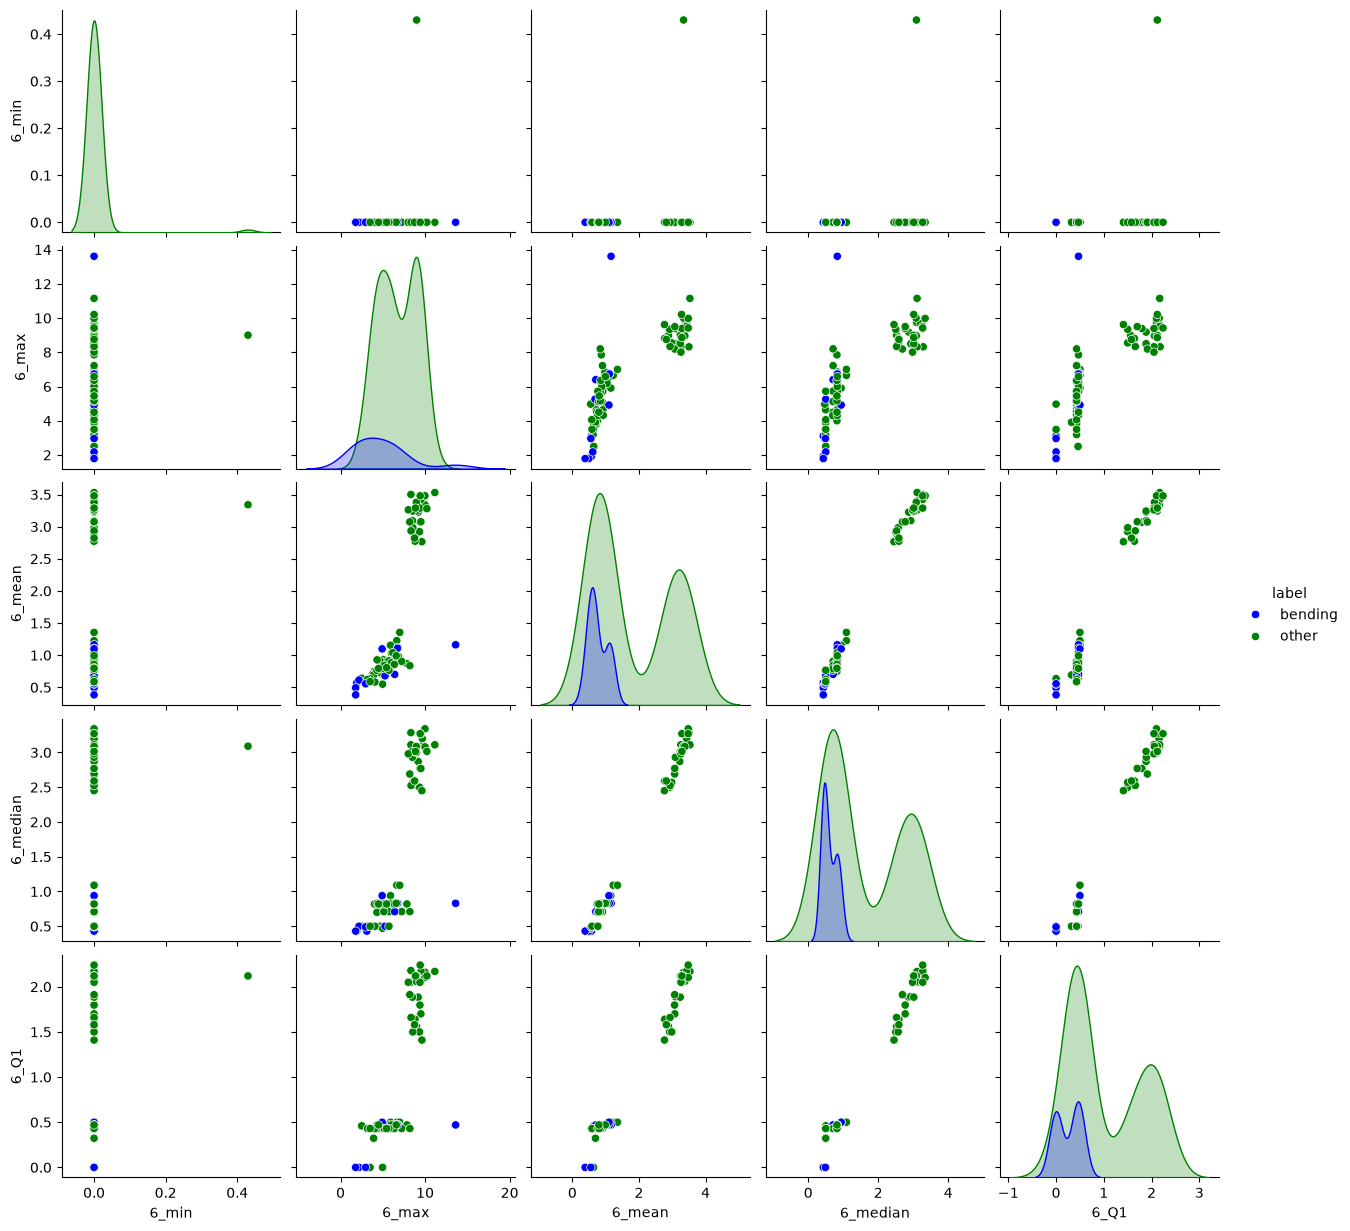

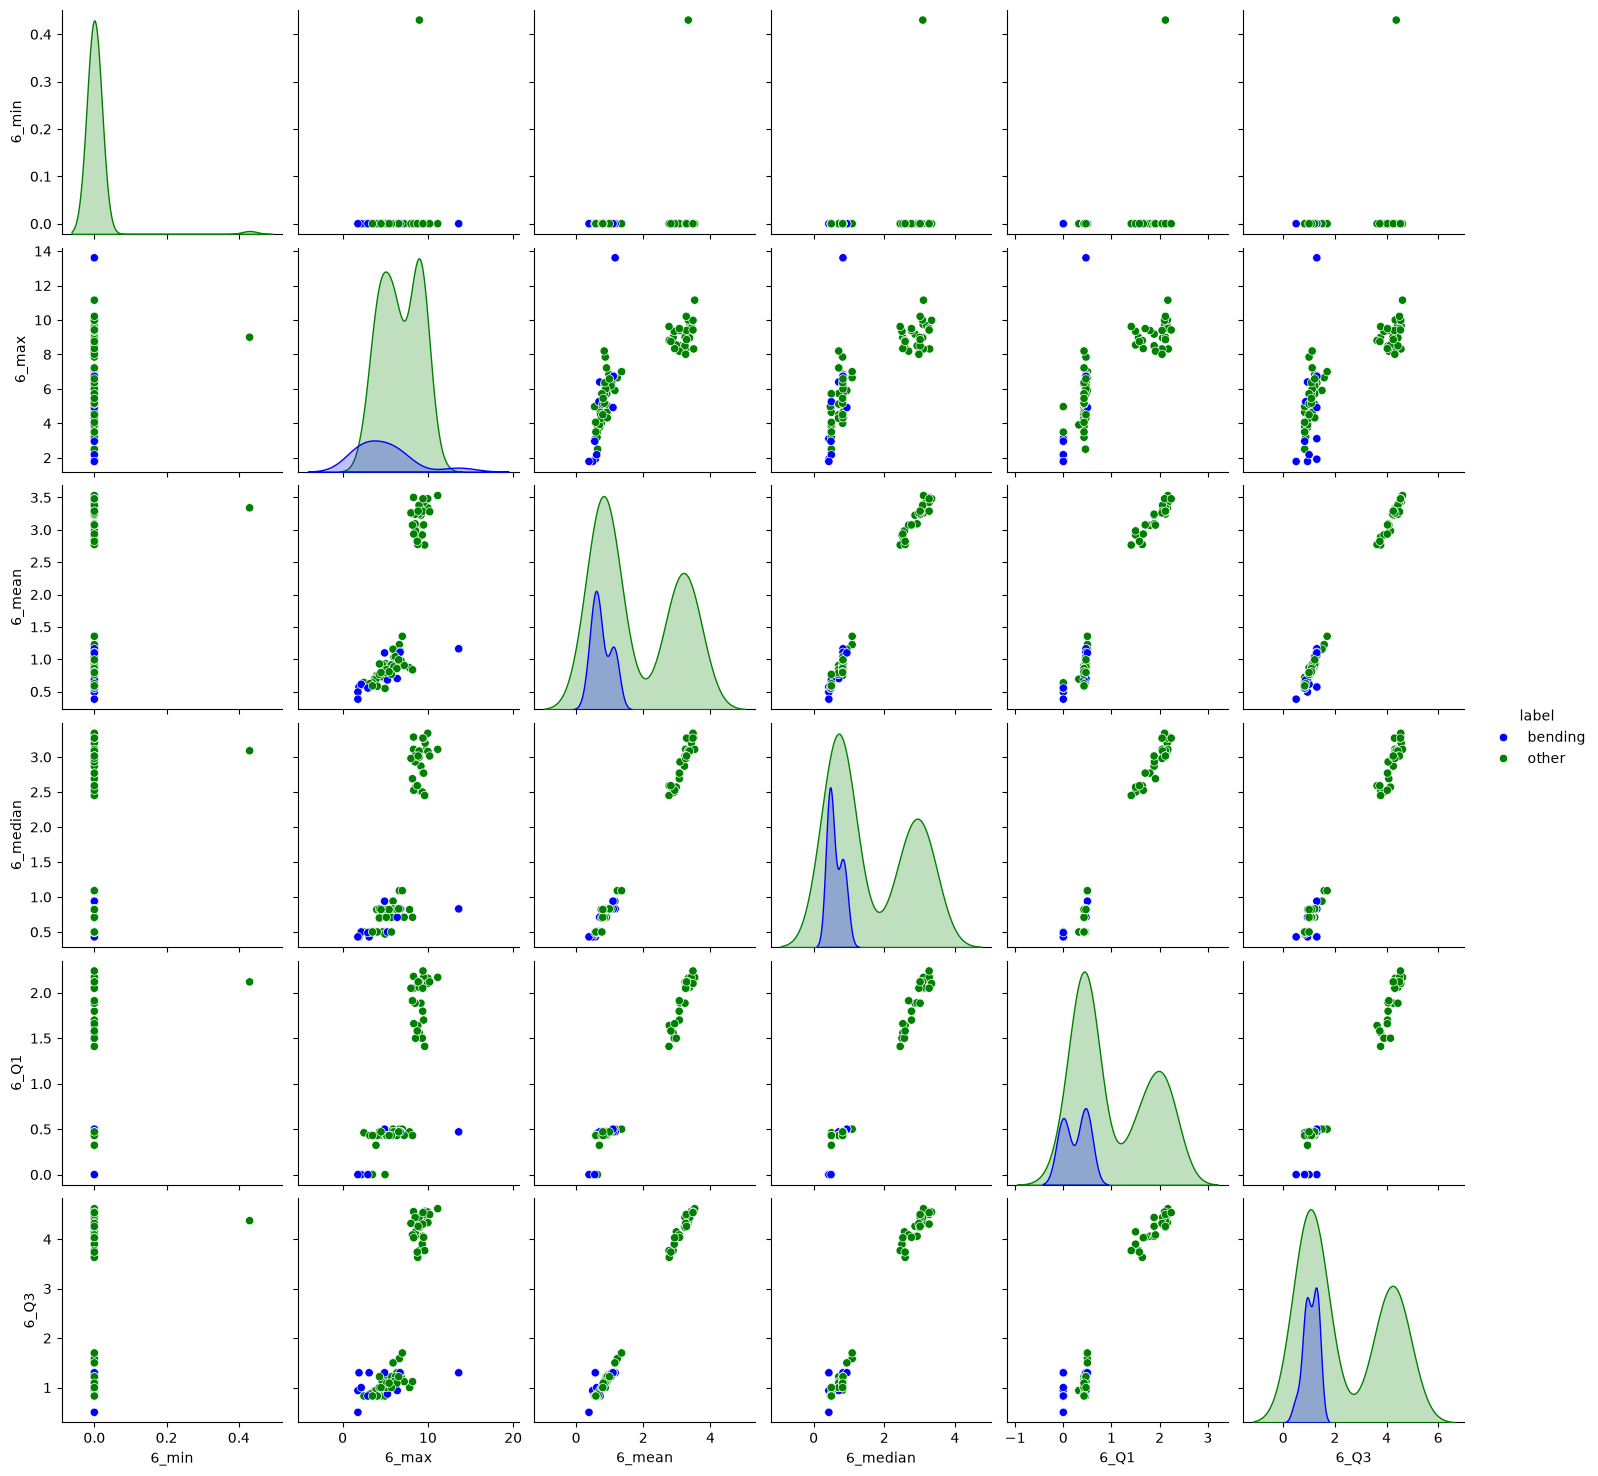

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

select_cols = [1,2,6]
stats_cols = ["min","max","mean","median","Q1","Q3"]
feature_ext["label"] = np.where(feature_ext["label"].str.contains("bending"), "bending", "other")


for sc in select_cols:
    new_cols = []
    for ss in stats_cols:
        new_cols.append(str(sc) + "_" + ss)
        sns.pairplot(feature_ext[new_cols + ["label"]], hue = "label", palette = {"bending": "Blue", "other": "Green"})


plt.show()


#### ii. Splitted Plots

In [6]:
split_df = training_data.copy()
split_df["folder"] = split_df["label"]
split_df["label"] = np.where(split_df["folder"].str.startswith("bending"), "bending","other")

groupings = split_df.groupby(["folder","sequence"])
position = groupings.cumcount()
instance_length = groupings["sequence"].transform("size")

split_df["part"] = (position >= instance_length / 2).astype(int) + 1

print(split_df)

              0      1     2      3     4      5     6    label      sequence  \
960         0.0  42.00  0.71  21.25  0.43  30.00  0.00  bending  dataset3.csv   
961       250.0  41.50  0.50  20.25  1.48  31.25  1.09  bending  dataset3.csv   
962       500.0  41.50  0.50  14.25  1.92  33.00  0.00  bending  dataset3.csv   
963       750.0  40.75  0.83  15.75  0.43  33.00  0.00  bending  dataset3.csv   
964      1000.0  40.00  0.71  20.00  2.74  32.75  0.43  bending  dataset3.csv   
...         ...    ...   ...    ...   ...    ...   ...      ...           ...   
42234  118750.0  31.50  1.66  12.50  3.20  14.25  4.44    other  dataset9.csv   
42235  119000.0  27.33  1.25  11.33  0.94  20.00  4.00    other  dataset9.csv   
42236  119250.0  37.80  7.68  14.20  2.48  17.25  0.83    other  dataset9.csv   
42237  119500.0  33.75  1.30  15.75  5.21  16.50  2.69    other  dataset9.csv   
42238  119750.0  32.67  3.09  18.67  0.47  14.00  3.16    other  dataset9.csv   

       test_splitting    fo

In [7]:
cols = [1, 2, 6]
statistics = ["min", "max", "mean", "median", "Q1", "Q3"]

split_features = split_df.groupby(["folder", "sequence", "label", "part"])[cols].agg(
    ["min", "max", "mean", "median", lambda x: x.quantile(0.25), lambda x: x.quantile(0.75)])

renamed_cols = []
for c in cols:
    for s in statistics:
        renamed_cols.append(str(c) + "_" + s)

split_features.columns = renamed_cols

print(split_features)

                                    1_min  1_max     1_mean  1_median  \
folder   sequence     label   part                                      
bending1 dataset3.csv bending 1     36.50  46.50  44.057167     44.50   
                              2     35.00  47.40  43.851833     43.50   
         dataset4.csv bending 1     33.75  47.75  43.278875     45.00   
                              2     33.00  46.00  41.080750     42.00   
         dataset5.csv bending 1     33.00  45.75  41.621208     42.33   
...                                   ...    ...        ...       ...   
walking  dataset7.csv other   2     20.33  47.67  34.779625     35.00   
         dataset8.csv other   1     18.33  44.00  34.836458     35.75   
                              2     22.67  45.75  34.363292     35.00   
         dataset9.csv other   1     23.00  42.75  34.329333     34.71   
                              2     15.50  43.67  34.122417     34.75   

                                       1_Q1     1_

In [8]:
split_features = split_features.unstack("part")

split_names = []
for c in cols:
    for s in statistics:
        for p in [1,2]:
            split_names.append(str(c) + "_" + s + "_p" + str(p))


split_features.columns = split_names

split_features = split_features.reset_index()

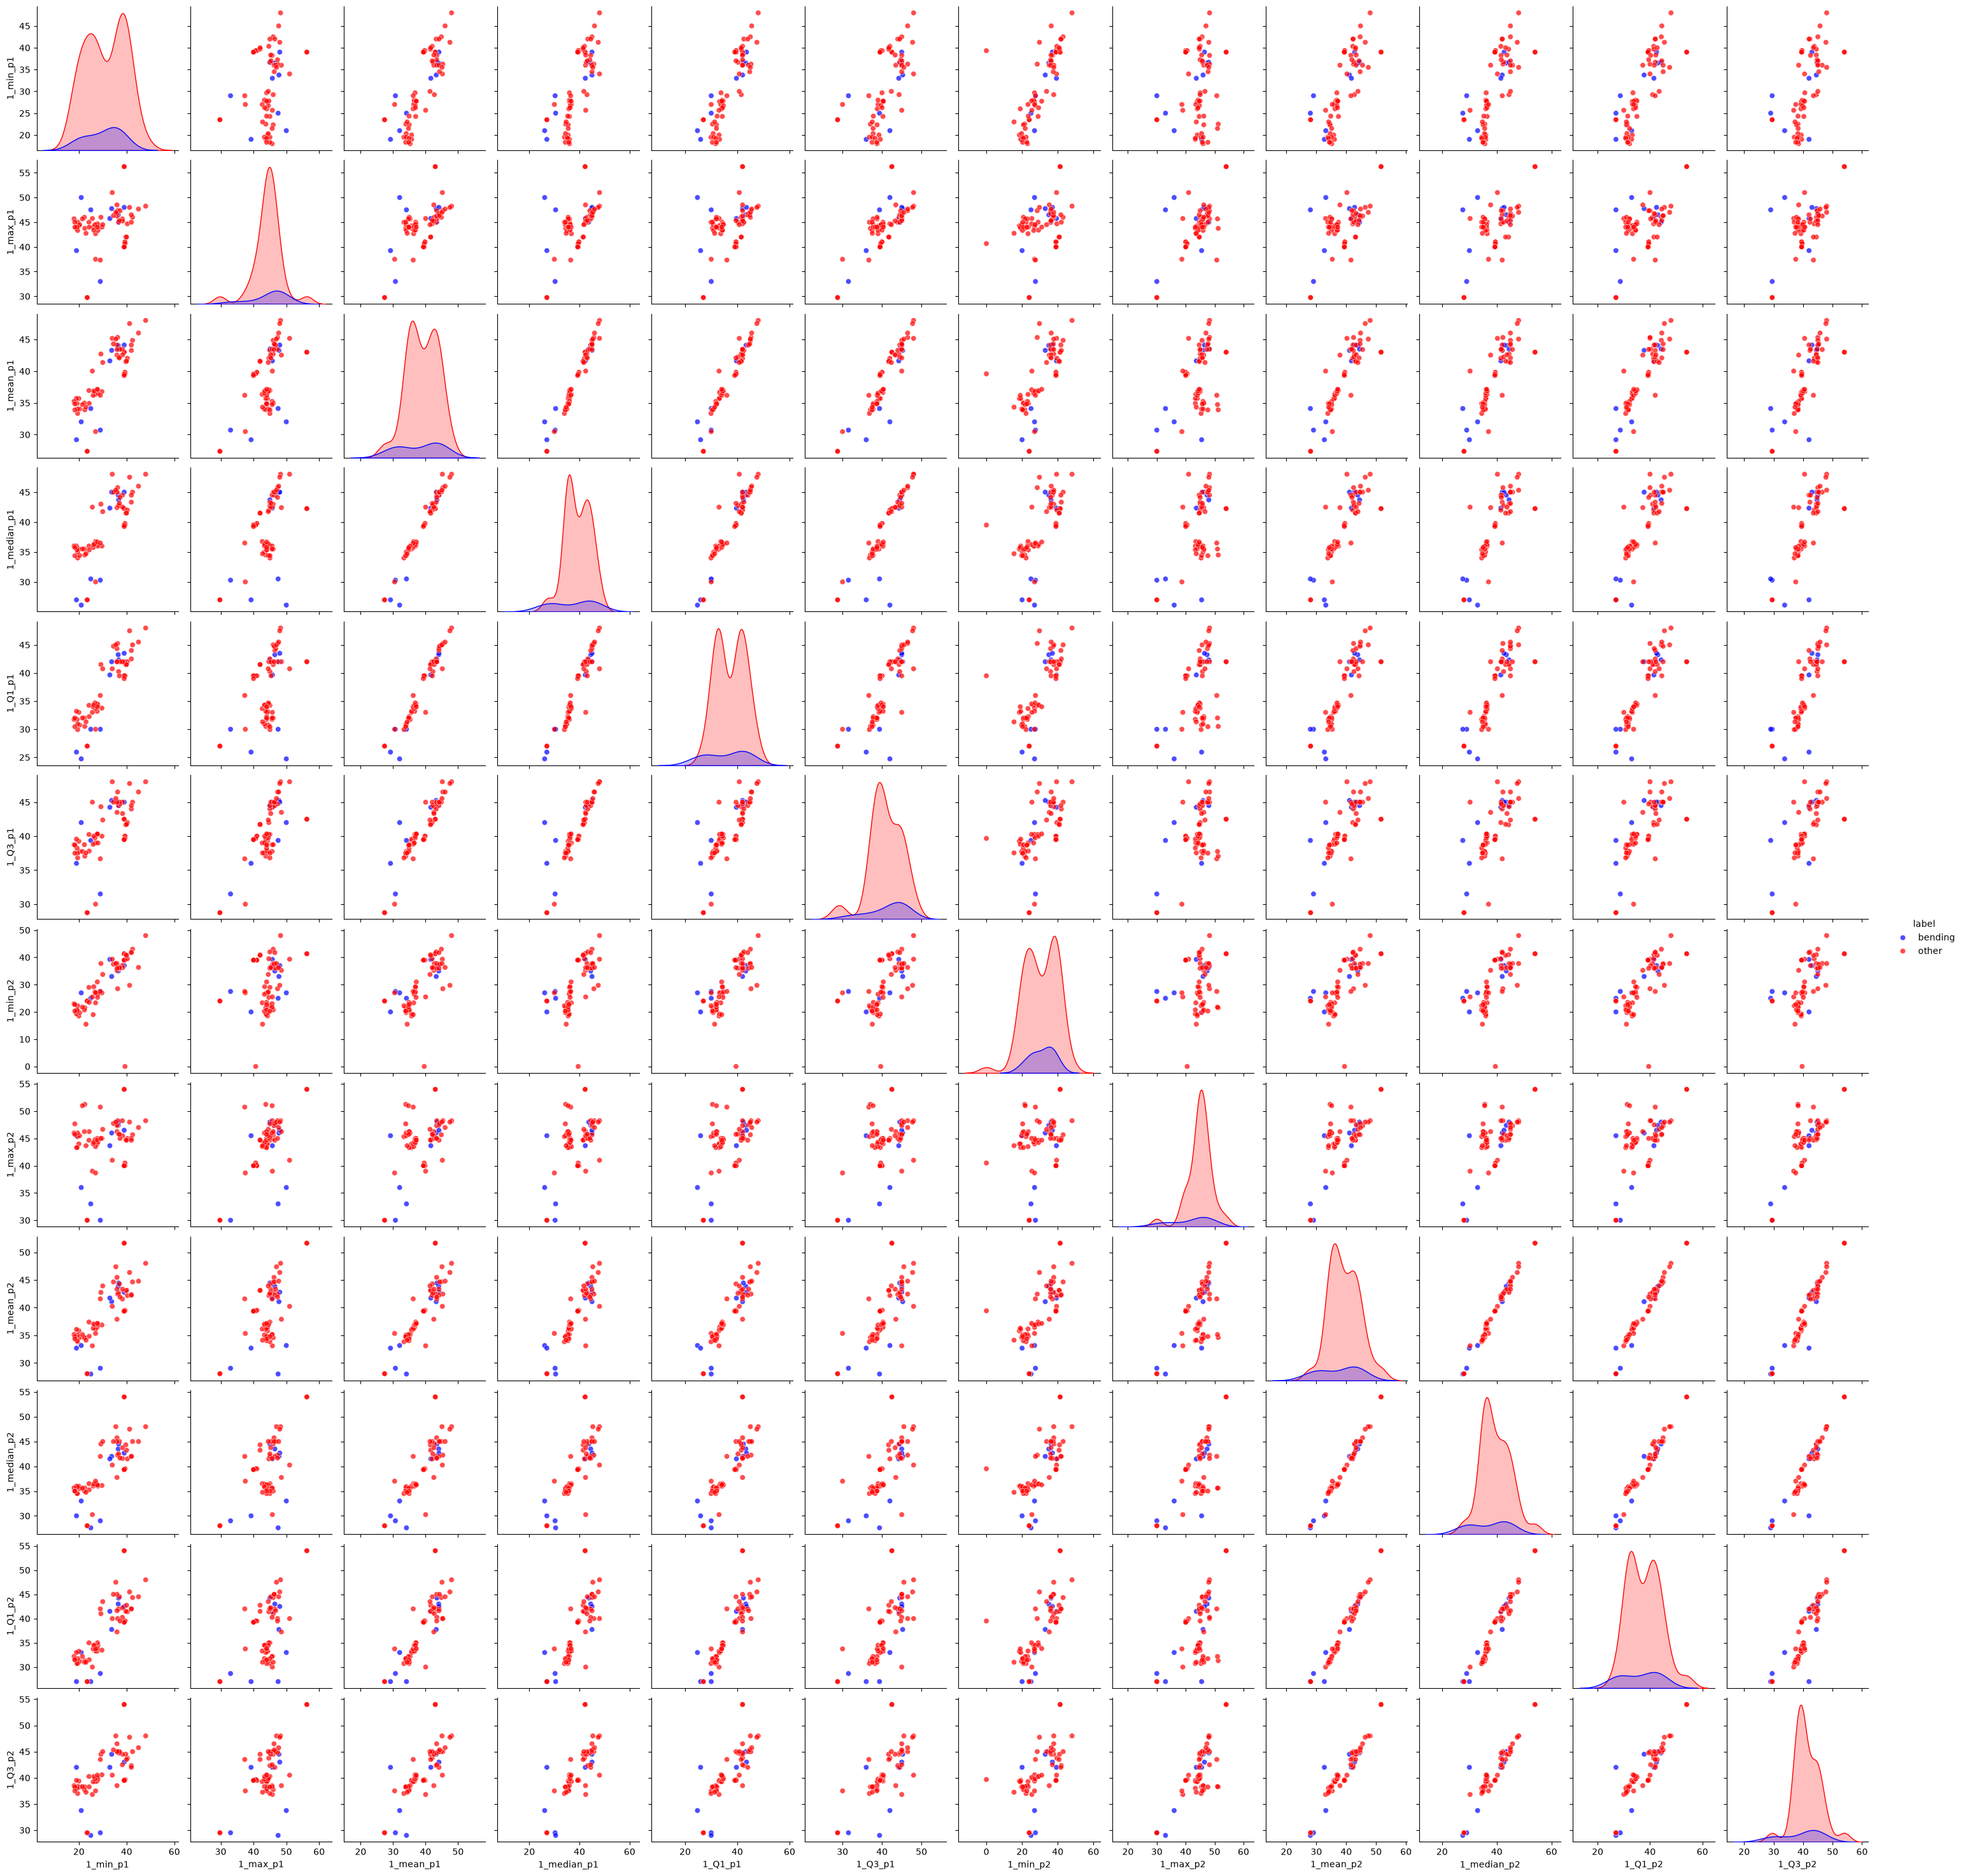

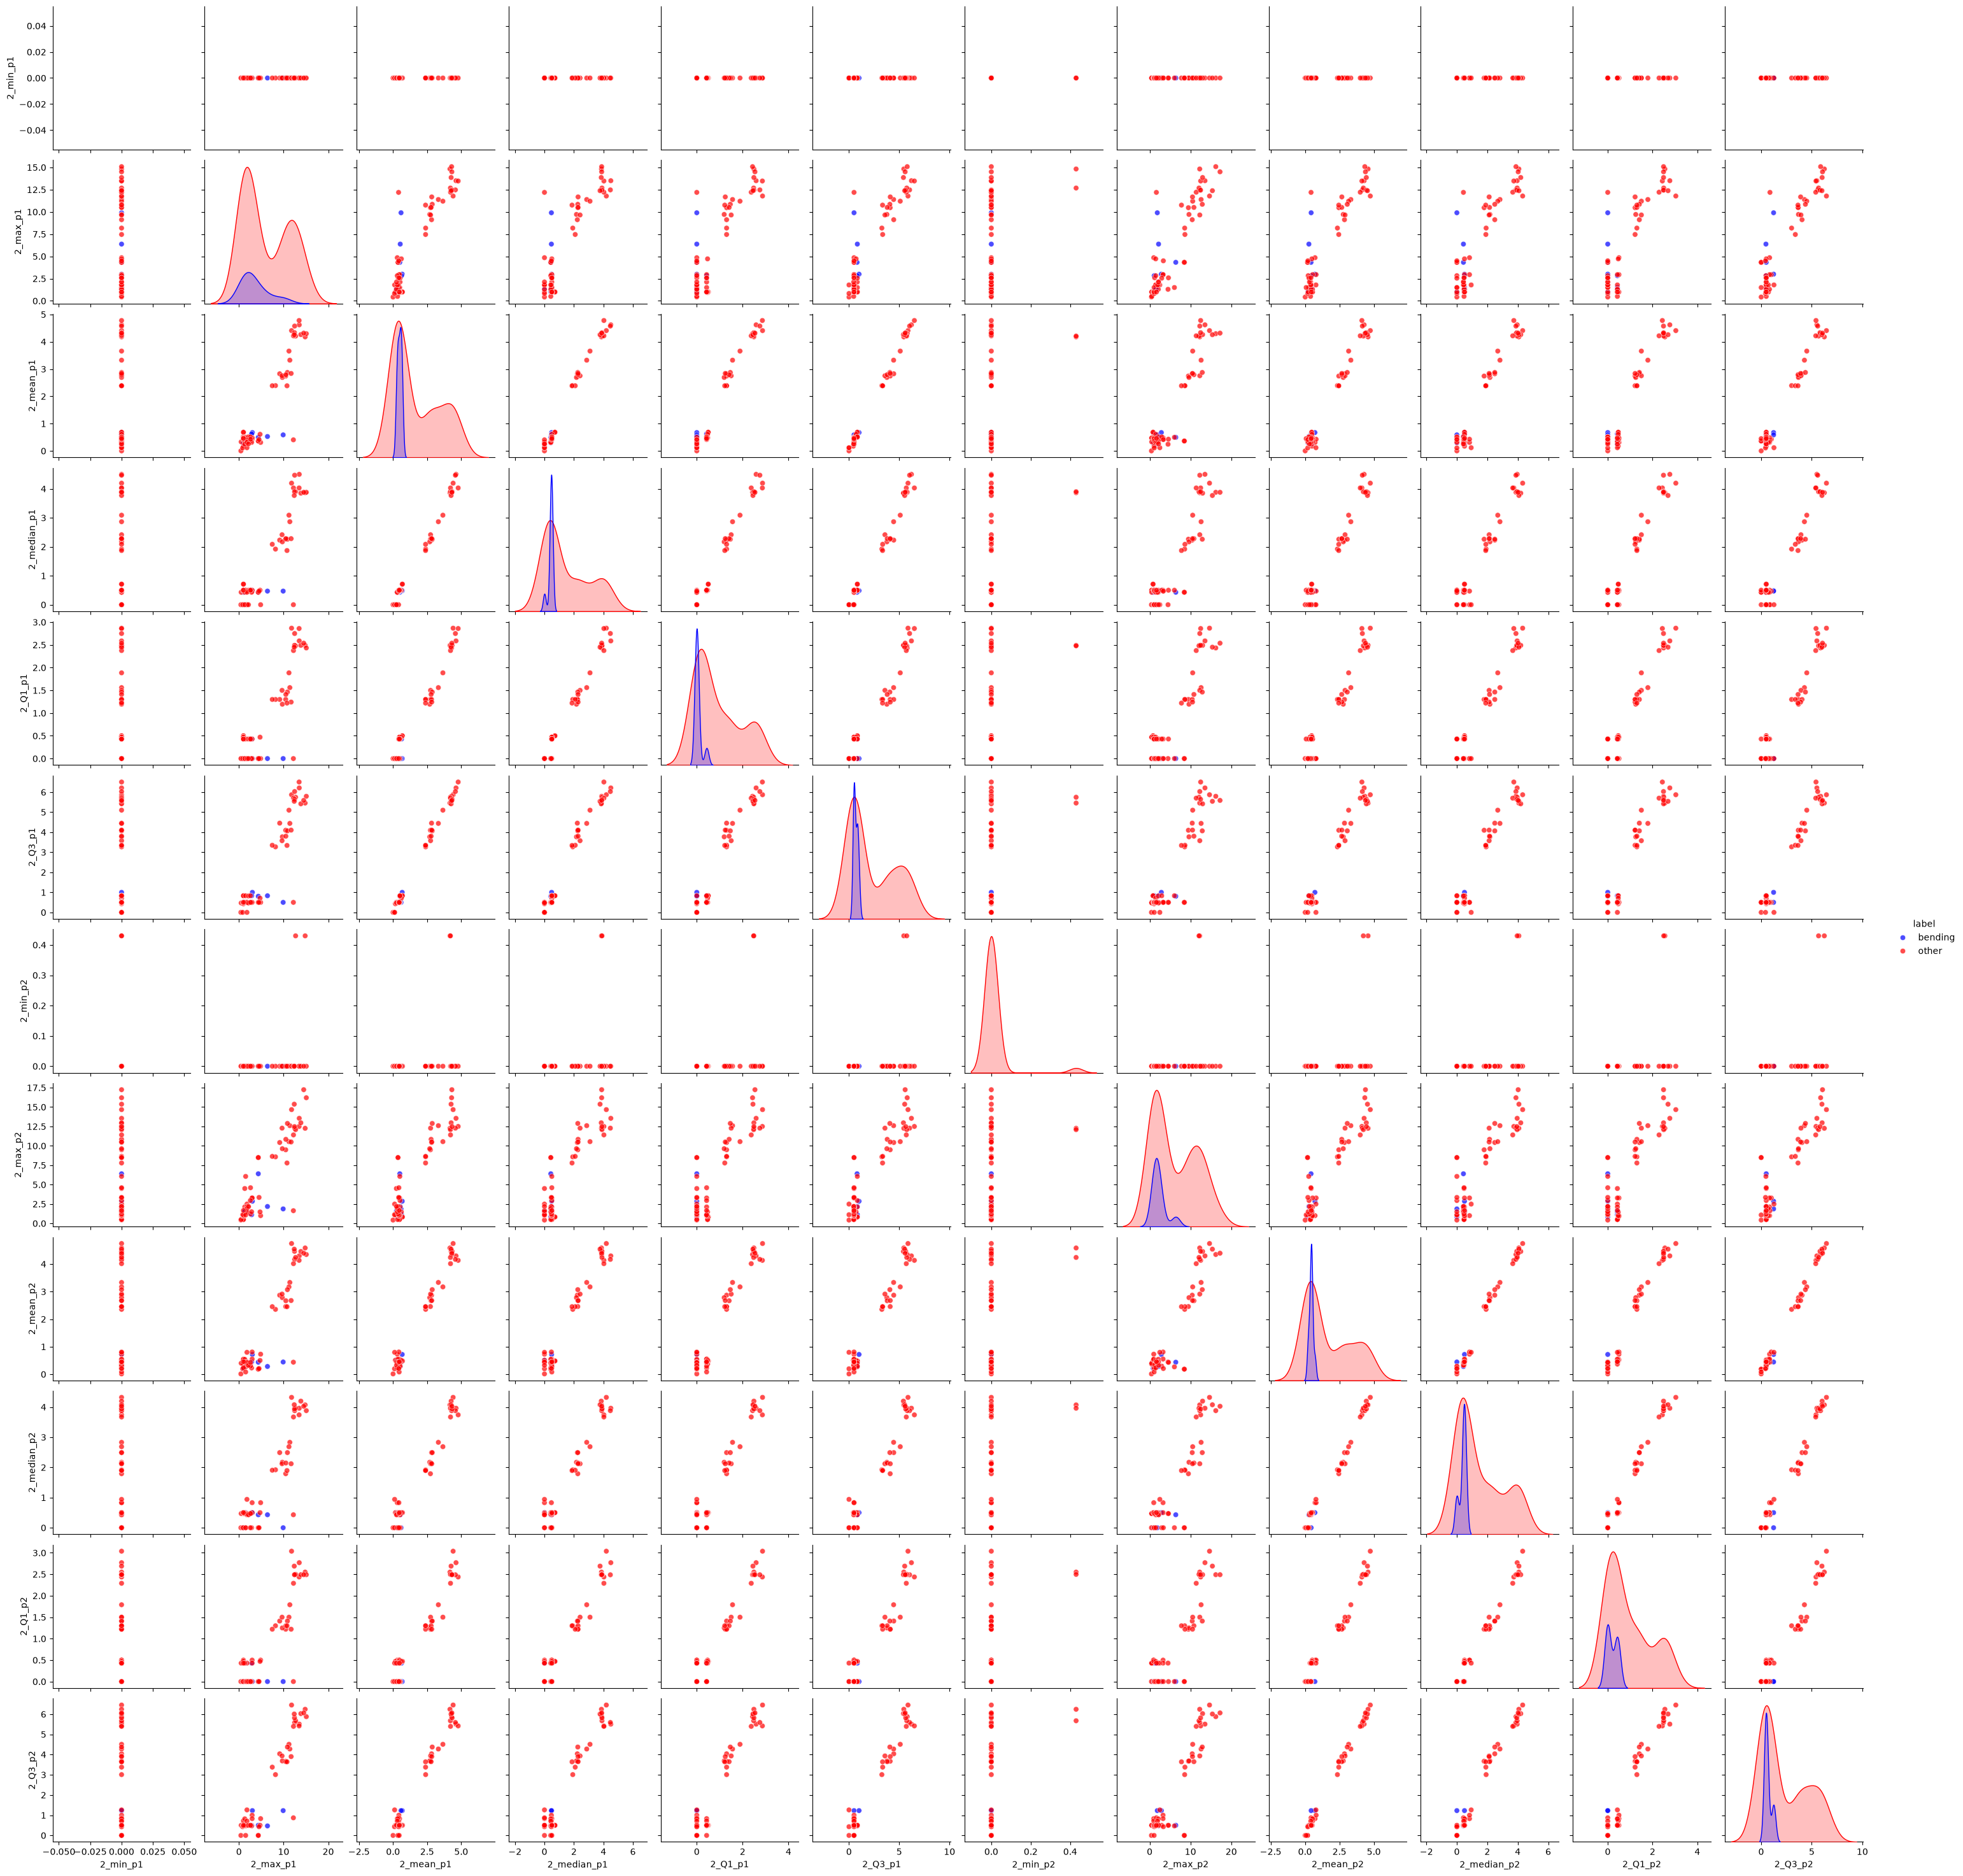

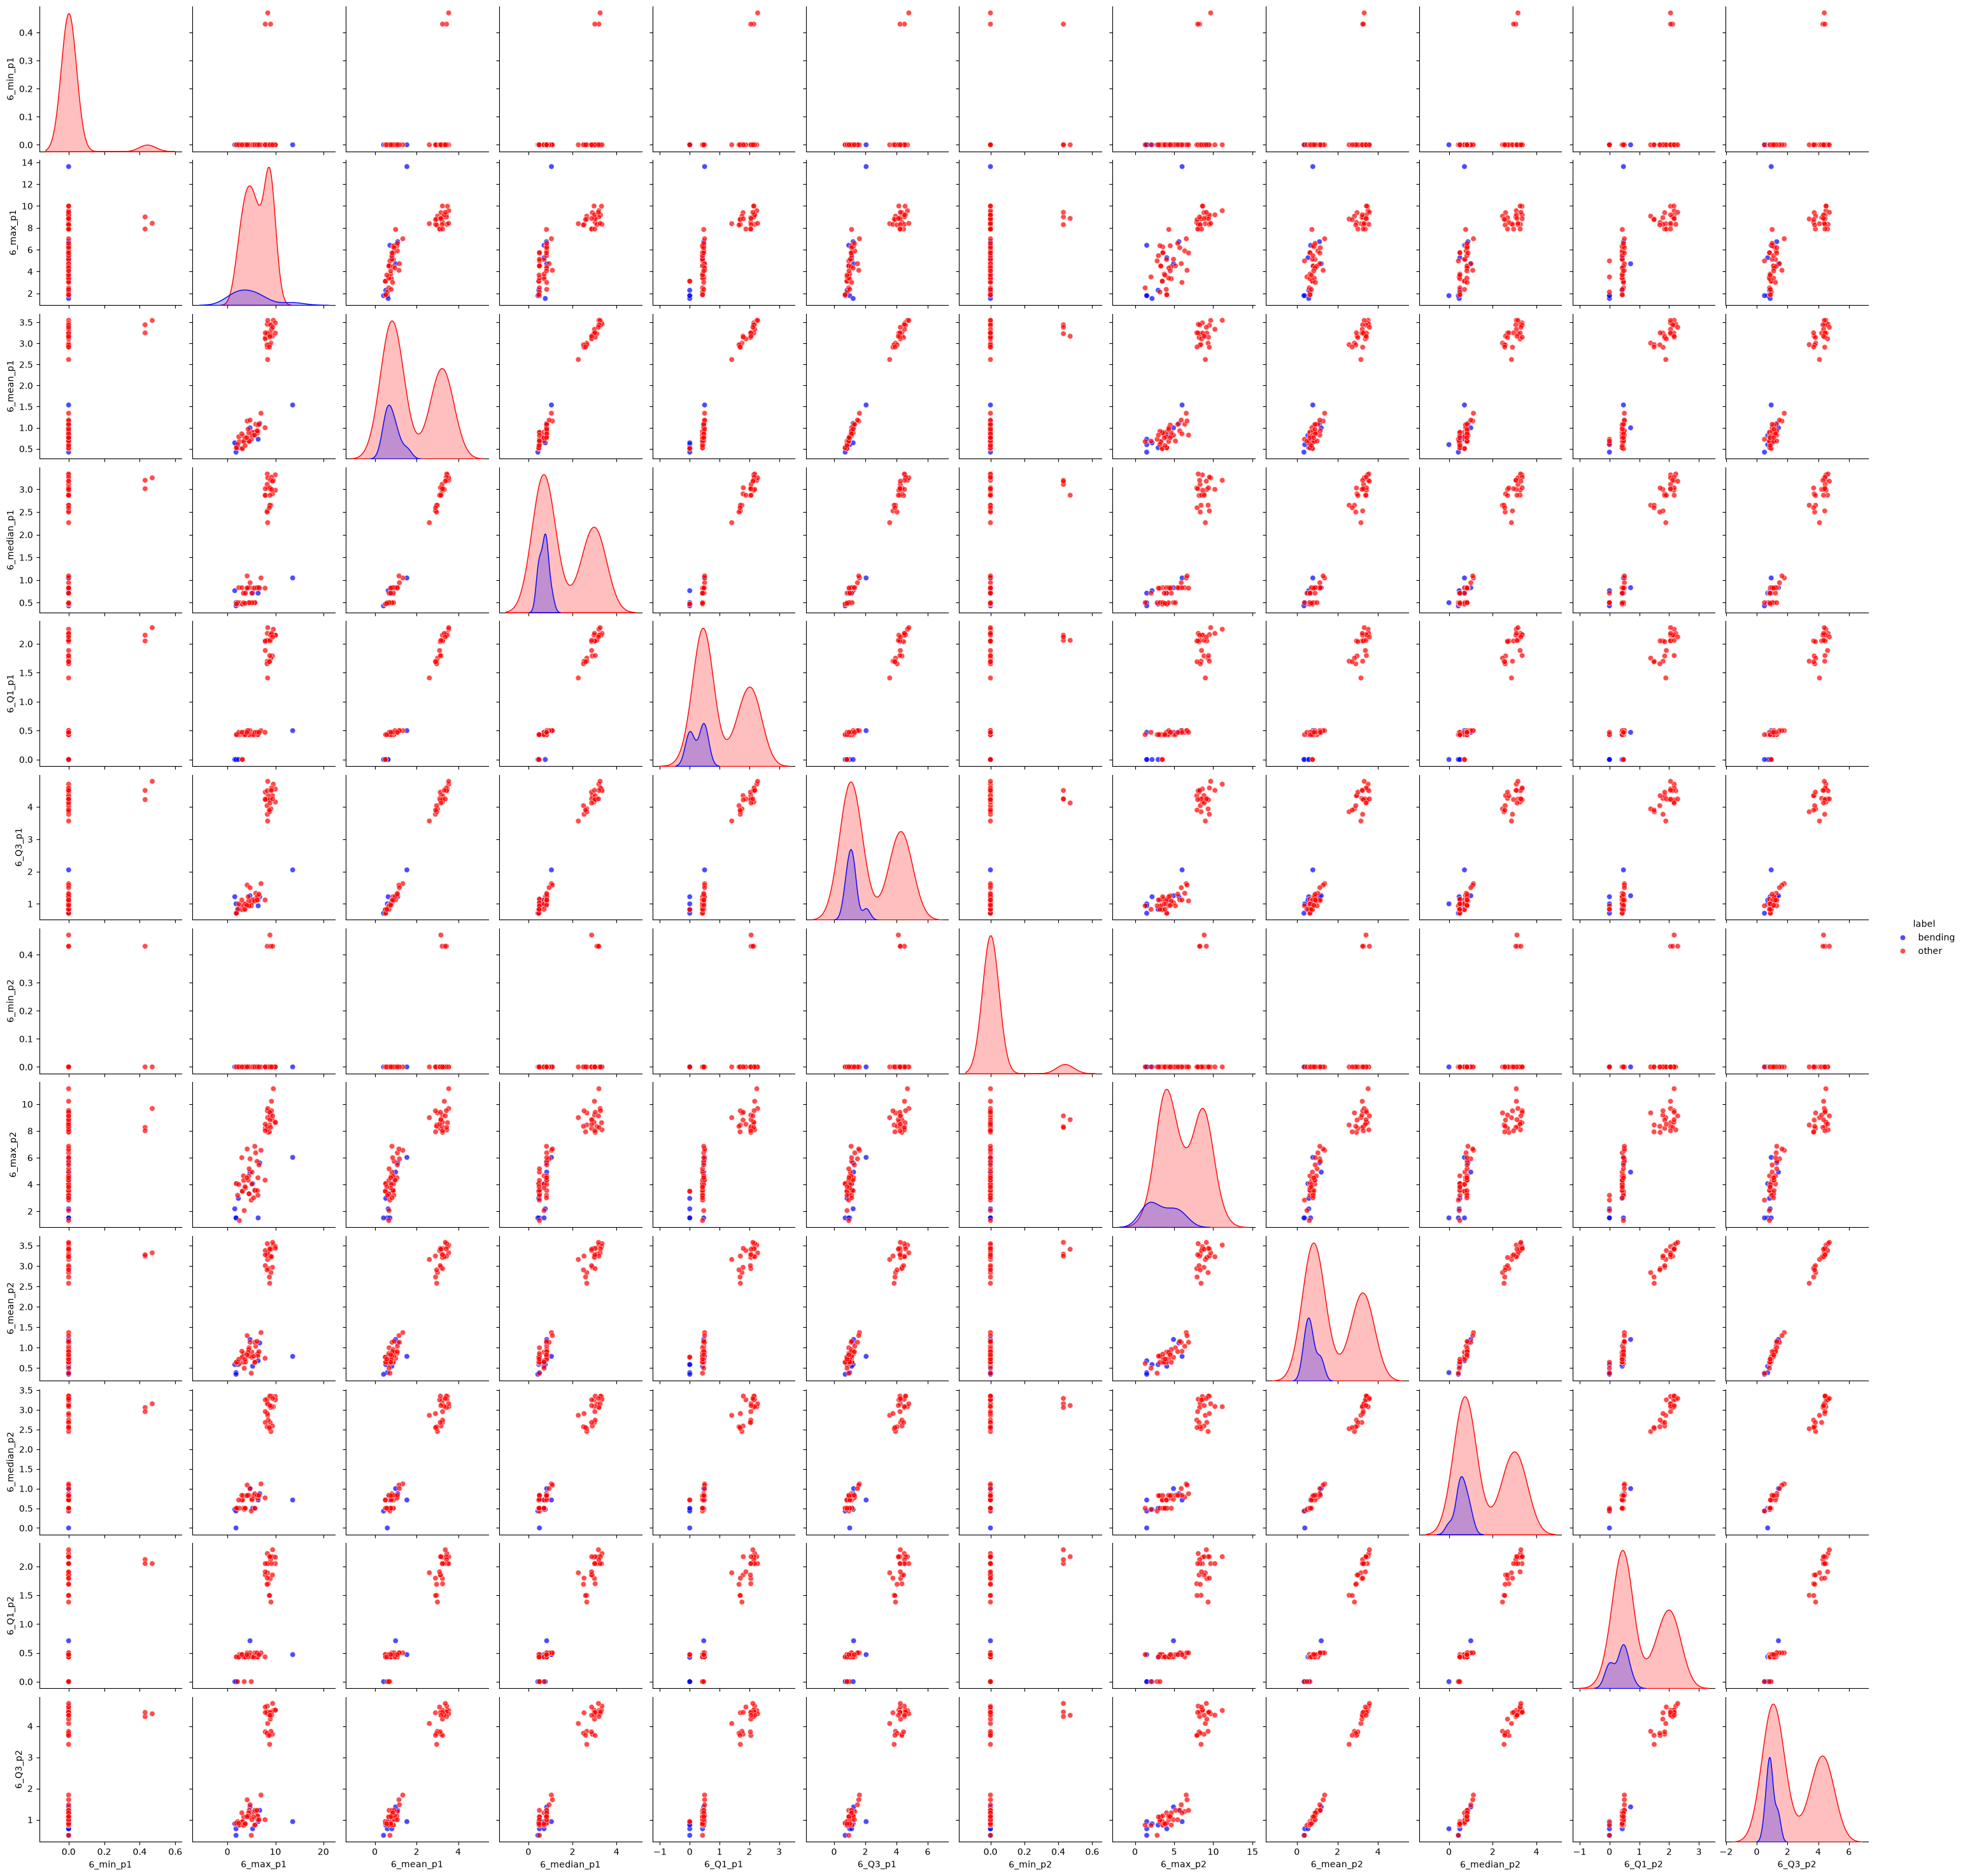

In [9]:
for c in cols:
    new_col_names = []
    for p in ["p1","p2"]:
        for s in statistics:
            new_col_names.append(f"{c}_{s}_{p}")

    sns.pairplot(split_features[new_col_names + ["label"]], hue = "label",palette={"bending": "Blue", "other": "Red"}, plot_kws={"alpha" : 0.7})

plt.show()

As a result of the splitting of the training set, and now having plots of both parts of the training set after filtering through the criteria stated in the problem. I see major differences in the clusterings of features between this problem and 2a, where the clusters here show more of the split between bending and others compared to what was shown in 2a. 

#### iii. Time Series Segments

In [10]:
training_seg = training_data.copy()
training_seg["folder"] = training_seg["label"]
training_seg["y"] = training_seg["folder"].str.startswith("bending").astype(int)

cols = [1,2,3,4,5,6]
stats = ["min", "max", "mean", "median", "Q1", "Q3"]

my_instances = list(training_seg.groupby(["folder","sequence"], sort = False))
list_of_ys = []
for k,g in my_instances:
    list_of_ys.append(g["y"].iloc[0])

y = np.array(list_of_ys)


In [11]:
X_for_l = {}
names_for_l = {}

for l in range(1,21):
    my_rows = []
    for k,g in my_instances:
        features = []
        for c in cols:
            split_chunks = np.array_split(g[c].to_numpy(dtype=float), l)
            for sc in split_chunks:
                features = features + [sc.min(),sc.max(),sc.mean(),np.median(sc), np.percentile(sc,25),np.percentile(sc,75)]
        my_rows.append(features)

    temp_names = []
    for c in cols:
        for k in range(1,l + 1):
            for s in stats:
                temp_names.append(f"{c}_{s}_{k}")
    names_for_l[l] = temp_names
    X_for_l[l] = pd.DataFrame(np.array(my_rows),columns=temp_names)
    


In [13]:
#Cross validation using 5 k fold
from sklearn.model_selection import StratifiedKFold, GridSearchCV
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression

k_fold = StratifiedKFold(n_splits=5,shuffle=True)
pval_grid = list(range(1,21))

results = []


for l in range(1,21):
    my_pipe = Pipeline([("scale", StandardScaler()),
                        ("rfe", RFE(LogisticRegression(C =1e6,max_iter=100), step=0.1)),
                        ("clf",LogisticRegression(C =1e6, max_iter = 100))])
    my_grid = GridSearchCV(my_pipe,param_grid={"rfe__n_features_to_select" : pval_grid},cv = k_fold,scoring = "accuracy")
    my_grid.fit(X_for_l[l],y)
    
    results.append((l,my_grid.best_params_["rfe__n_features_to_select"],my_grid.best_score_))

df_results = pd.DataFrame(results,columns=["l","best_p","cv_accur"])
print(df_results)

row_best = df_results.sort_values(["cv_accur","l","best_p"], ascending=[False,True,True]).iloc[0]
l_best, p_best = int(row_best["l"]),int(row_best["best_p"])





     l  best_p  cv_accur
0    1      12  1.000000
1    2       2  0.971429
2    3       6  0.971429
3    4      13  0.985714
4    5      13  0.940659
5    6       9  0.942857
6    7       5  0.957143
7    8       5  0.956044
8    9       5  0.941758
9   10      19  0.940659
10  11       2  0.970330
11  12       7  0.942857
12  13       3  0.971429
13  14       2  0.942857
14  15      17  0.941758
15  16      10  0.985714
16  17      15  0.971429
17  18       7  0.971429
18  19       9  0.956044
19  20      18  0.969231


In [15]:
import warnings
warnings.filterwarnings("ignore")

#Pruning
l_selected = {}
best_models = {}
rows = []

y_arry = np.asarray(y)

for l in range(1,21):
    x = X_for_l[l]
    p = df_results.loc[df_results["l"] == 1, "best_p"].iloc[0]

    my_scaler = StandardScaler().fit(x)
    X_s = pd.DataFrame(my_scaler.transform(x))
    my_rfe = RFE(LogisticRegression(C = 1e6),n_features_to_select=p)
    my_rfe.fit(X_s,y_arry)

    selected = list(X_s.columns[my_rfe.support_])
    
    #Backwards Elimination
    pruning = True
    while len(selected) > 1:
        log_model = sm.Logit(y_arry,sm.add_constant(X_s[selected])).fit(disp = 0)
        pvalues = log_model.pvalues.drop("const")
        if pvalues.max() <= 0.05:
            break
        selected.remove(pvalues.idxmax())
    pruned_log = LogisticRegression(C = 1e6).fit(X_s[selected],y_arry)
    
    l_selected[l] = selected
    best_models[l] = (my_scaler,pruned_log)
    rows.append((l,p,pruned_log.score(X_s[selected],y_arry)))

pruned_summaryTable = pd.DataFrame(rows,columns=["l","best_p","training_accur"])
print(pruned_summaryTable)



     l  best_p  training_accur
0    1      12        0.971014
1    2      12        0.913043
2    3      12        0.985507
3    4      12        0.971014
4    5      12        0.971014
5    6      12        0.971014
6    7      12        0.971014
7    8      12        0.913043
8    9      12        0.942029
9   10      12        0.956522
10  11      12        0.971014
11  12      12        0.971014
12  13      12        0.985507
13  14      12        0.985507
14  15      12        0.956522
15  16      12        0.971014
16  17      12        0.956522
17  18      12        0.971014
18  19      12        0.971014
19  20      12        0.985507


In [18]:
#refitting logistic regression model
from sklearn.model_selection import cross_val_score
X = X_for_l[l_best]
pruned_x = X.iloc[:,l_selected[l_best]]
print(pruned_x.shape)

pruned_pipe = Pipeline([("scaled",StandardScaler()),("clf",LogisticRegression(C=1e6,max_iter=100))])

cross_scores = cross_val_score(pruned_pipe,pruned_x,y_arry,cv = k_fold,scoring = "accuracy")
print("Fold Accuracy: ",cross_scores)
print("Mean Accuracy: ",cross_scores.mean(),"+/-",cross_scores.std())

(69, 1)
Fold Accuracy:  [1.         0.92857143 1.         0.92857143 0.92307692]
Mean Accuracy:  0.9560439560439562 +/- 0.035945993920431026


The right way to use cross-fold validation for this problem, was to use 5 folds and first fit a logisticRegression model to it. After fitting the model for the first time and given the results, you would then prune the dataframe down to the p features stated prior. After doing that then you would fit another logisticRegression model based on the pruned information and print the results to a table. The cross-fold validation helps to pick out the best (l,p) pairing for this.

#### iv. Confusion Matrix

In [24]:
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score

my_scaler,classification = best_models[l_best]

my_feats = l_selected[l_best]

X_s = pd.DataFrame(my_scaler.transform(X))
final_x = X_s[my_feats]

y_prediction = classification.predict(final_x)
y_probability = classification.predict_proba(final_x)[:,1]

my_matrix = confusion_matrix(y_arry,y_prediction)
print(my_matrix)

[[59  1]
 [ 1  8]]


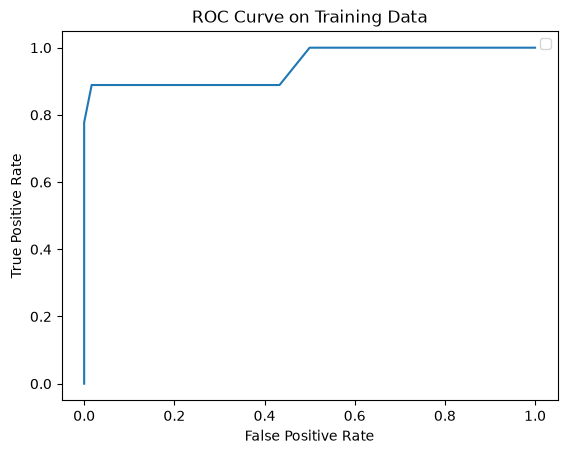

AUC Score:  0.9472222222222222


In [26]:
#Building the ROC and AUC curves
false_pos_rate, true_pos_rate, threshold = roc_curve(y_arry,y_probability)
my_auc = roc_auc_score(y_arry,y_probability)

plt.plot(false_pos_rate,true_pos_rate)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve on Training Data")

plt.legend()
plt.show()

print("AUC Score: ", my_auc)

In [27]:
#Finding p-values and beta
new_log_model = sm.Logit(y_arry,sm.add_constant(final_x)).fit(disp = 0)

my_table = pd.DataFrame({"Beta" : new_log_model.params,
                         "Stand_Error" : new_log_model.bse,
                         "P-value" : new_log_model.pvalues})
print(my_table)

           Beta  Stand_Error   P-value
const -3.910037     1.050051  0.000196
25     3.344433     1.042796  0.001340


#### v. Test Classifier

In [36]:
from sklearn.metrics import accuracy_score

test_set = list(testing_data.groupby(["label","sequence"],sort = False))
list_of_y = []

for l,s in test_set:
    if l[0].startswith("bending"):
        list_of_y.append(1)
    else:
        list_of_y.append(0)

y_test = np.array(list_of_y)
test_rows = []

for l,s in test_set:
    my_features = []
    for c in cols:
        test_chunks = np.array_split(s[c].to_numpy(dtype=float),l_best)
        for tc in test_chunks:
            my_features += [tc.min(),tc.max(),tc.mean(),np.median(tc),np.percentile(tc,25),np.percentile(tc,75)]
    test_rows.append(my_features)

x_test = pd.DataFrame(np.array(test_rows),columns=names_for_l[l_best])

test_scaler,final_classification = best_models[l_best]
test_feats = l_selected[l_best]

test_X_s = pd.DataFrame(test_scaler.transform(x_test), columns=x_test.columns, index=x_test.index)
final_test_x = test_X_s.iloc[:, test_feats]

#Predicting and Evaluating
test_y_pred = final_classification.predict(final_test_x)
test_accuracy = accuracy_score(y_test,test_y_pred)
confu_matrix = confusion_matrix(y_test,test_y_pred)


print("Test Accuracy: ", test_accuracy)
print(confu_matrix)




Test Accuracy:  0.9473684210526315
[[15  0]
 [ 1  3]]


In [37]:
#Cross validation accuracy
cross_val_accur = df_results.loc[df_results["l"] == l_best,"cv_accur"].iloc[0]
base = max(y_test.mean(), 1 - y_test.mean())

print("Cross-Validation Accuracy: ",cross_val_accur)

Cross-Validation Accuracy:  1.0


#### vi. Separation

Yes my classes do seem well separated enough to cause issues in finding logistic regression parameters which is seen in the cross-validation accuracy of 1.0 which means there is something off in the parameters being chosen.

#### vii. Imbalance

Based on the confusion matrices I have made, i do not see an imbalance of classes between false positives and true positives.  The model had an AUC score of 94.72% with the confusion matrix having 15 true positives and 0 false positives in comparison. 

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [45]:
new_pval_grid = list(range(1,21))

new_results = []
temp = {}

for l in range(1,21):
    l1_pipe = Pipeline([("scale", StandardScaler()),
                        ("clf",LogisticRegression(penalty="l1", solver = "liblinear", max_iter = 100))])
    l1_grid = GridSearchCV(l1_pipe,param_grid={"clf__C" : new_pval_grid},cv = k_fold,scoring = "accuracy")
    l1_grid.fit(X_for_l[l],y)

    temp[l] = l1_grid
    new_results.append((l,l1_grid.best_params_["clf__C"],l1_grid.best_score_))

l1_results = pd.DataFrame(new_results,columns=["l","best_C","cv_accur"])
print(l1_results)
print("\n")

row_best = l1_results.sort_values(["cv_accur","l","best_C"], ascending=[False,True,True]).iloc[0]
l1_best, c_best = int(row_best["l"]),int(row_best["best_C"])

#Pruning
x = X_for_l[l1_best]
l1_scaler = StandardScaler().fit(x)
l1_x_s = pd.DataFrame(l1_scaler.transform(x),columns=x.columns)

l1_model = LogisticRegression(penalty="l1",solver="liblinear",C=c_best,max_iter = 100)
l1_model.fit(l1_x_s,y_arry)
coefficients = pd.Series(l1_model.coef_[0], index = x.columns)
pruned_names = list(coefficients[coefficients != 0].index)

refit_l1_model = LogisticRegression(C = 1e6,max_iter = 100).fit(l1_x_s[pruned_names],y_arry)

refit_rows = []
for l in range(1,21):
    searches = temp[l]
    scale_l1 = searches.best_estimator_.named_steps["scale"]
    clf_l1 = searches.best_estimator_.named_steps["clf"]

    l1_x = X_for_l[l]
    new_l1_x_s = pd.DataFrame(scale_l1.transform(l1_x),columns=l1_x.columns)
    other_names = list(l1_x.columns[clf_l1.coef_[0] != 0])

    if len(other_names) == 0:
        refit_rows.append(l,searches.best_params_["clf__C"],0,np.nan)
        continue

    new_refit_l1_model = LogisticRegression(C = 1e6, max_iter = 100).fit(new_l1_x_s[other_names],y_arry)
    refit_rows.append((l,searches.best_params_["clf__C"],len(other_names),new_refit_l1_model.score(new_l1_x_s[other_names],y_arry)))

    refit_l1_table = pd.DataFrame(refit_rows,columns=["l","best_c","kept_vals","training_accur"])
    print(refit_l1_table)




     l  best_C  cv_accur
0    1       2  0.957143
1    2       1  0.956044
2    3       2  0.971429
3    4       1  0.941758
4    5      11  0.971429
5    6       1  0.956044
6    7       6  0.971429
7    8       7  0.942857
8    9       1  0.942857
9   10      12  0.956044
10  11       1  0.941758
11  12       2  0.971429
12  13       2  0.957143
13  14       1  0.971429
14  15       2  0.927473
15  16       4  0.942857
16  17       7  0.957143
17  18       6  0.971429
18  19      18  0.985714
19  20       4  0.985714


   l  best_c  kept_vals  training_accur
0  1       2          8             1.0
   l  best_c  kept_vals  training_accur
0  1       2          8             1.0
1  2       1         11             1.0
   l  best_c  kept_vals  training_accur
0  1       2          8             1.0
1  2       1         11             1.0
2  3       2          9             1.0
   l  best_c  kept_vals  training_accur
0  1       2          8             1.0
1  2       1         11          

#### ii. Comparison

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

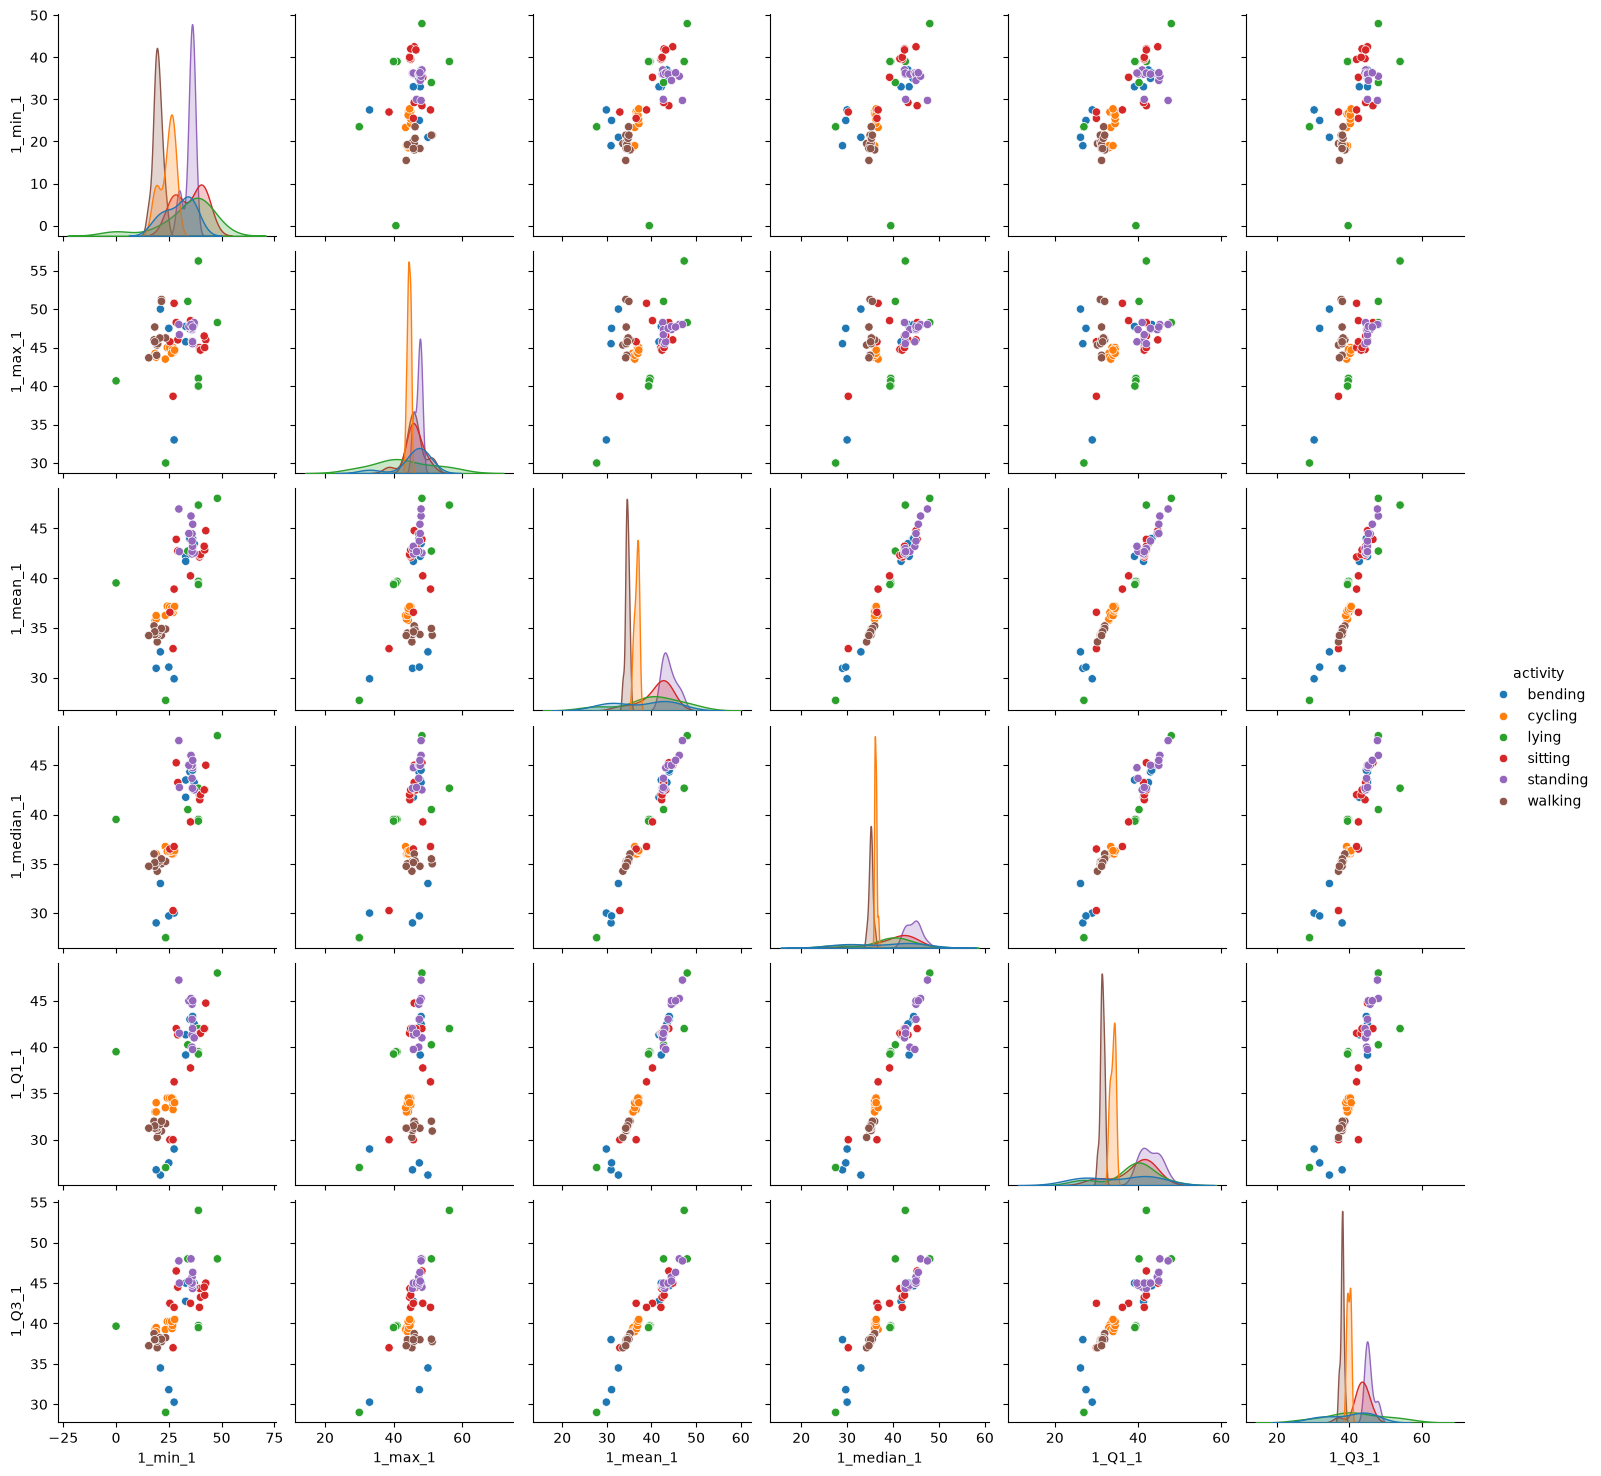

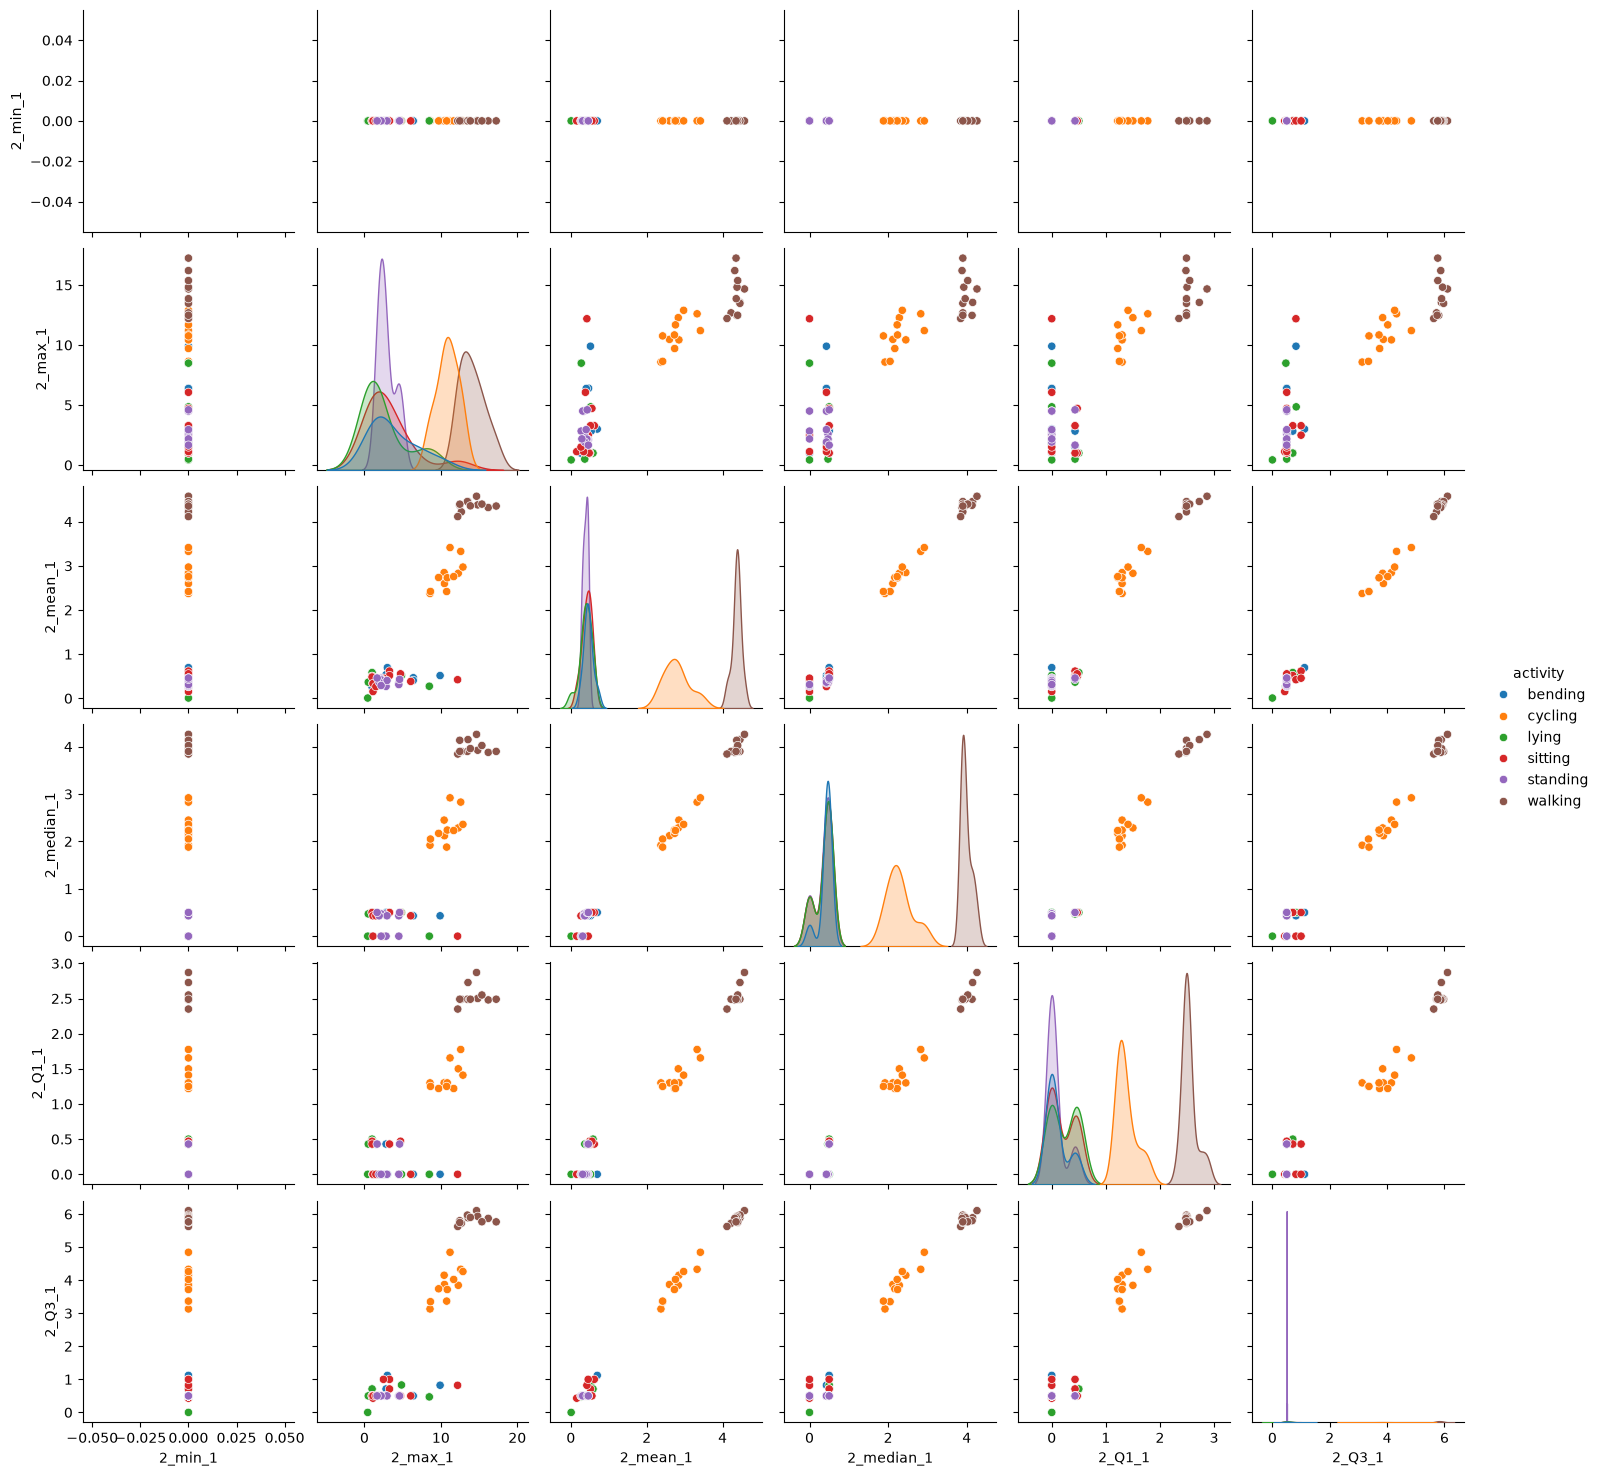

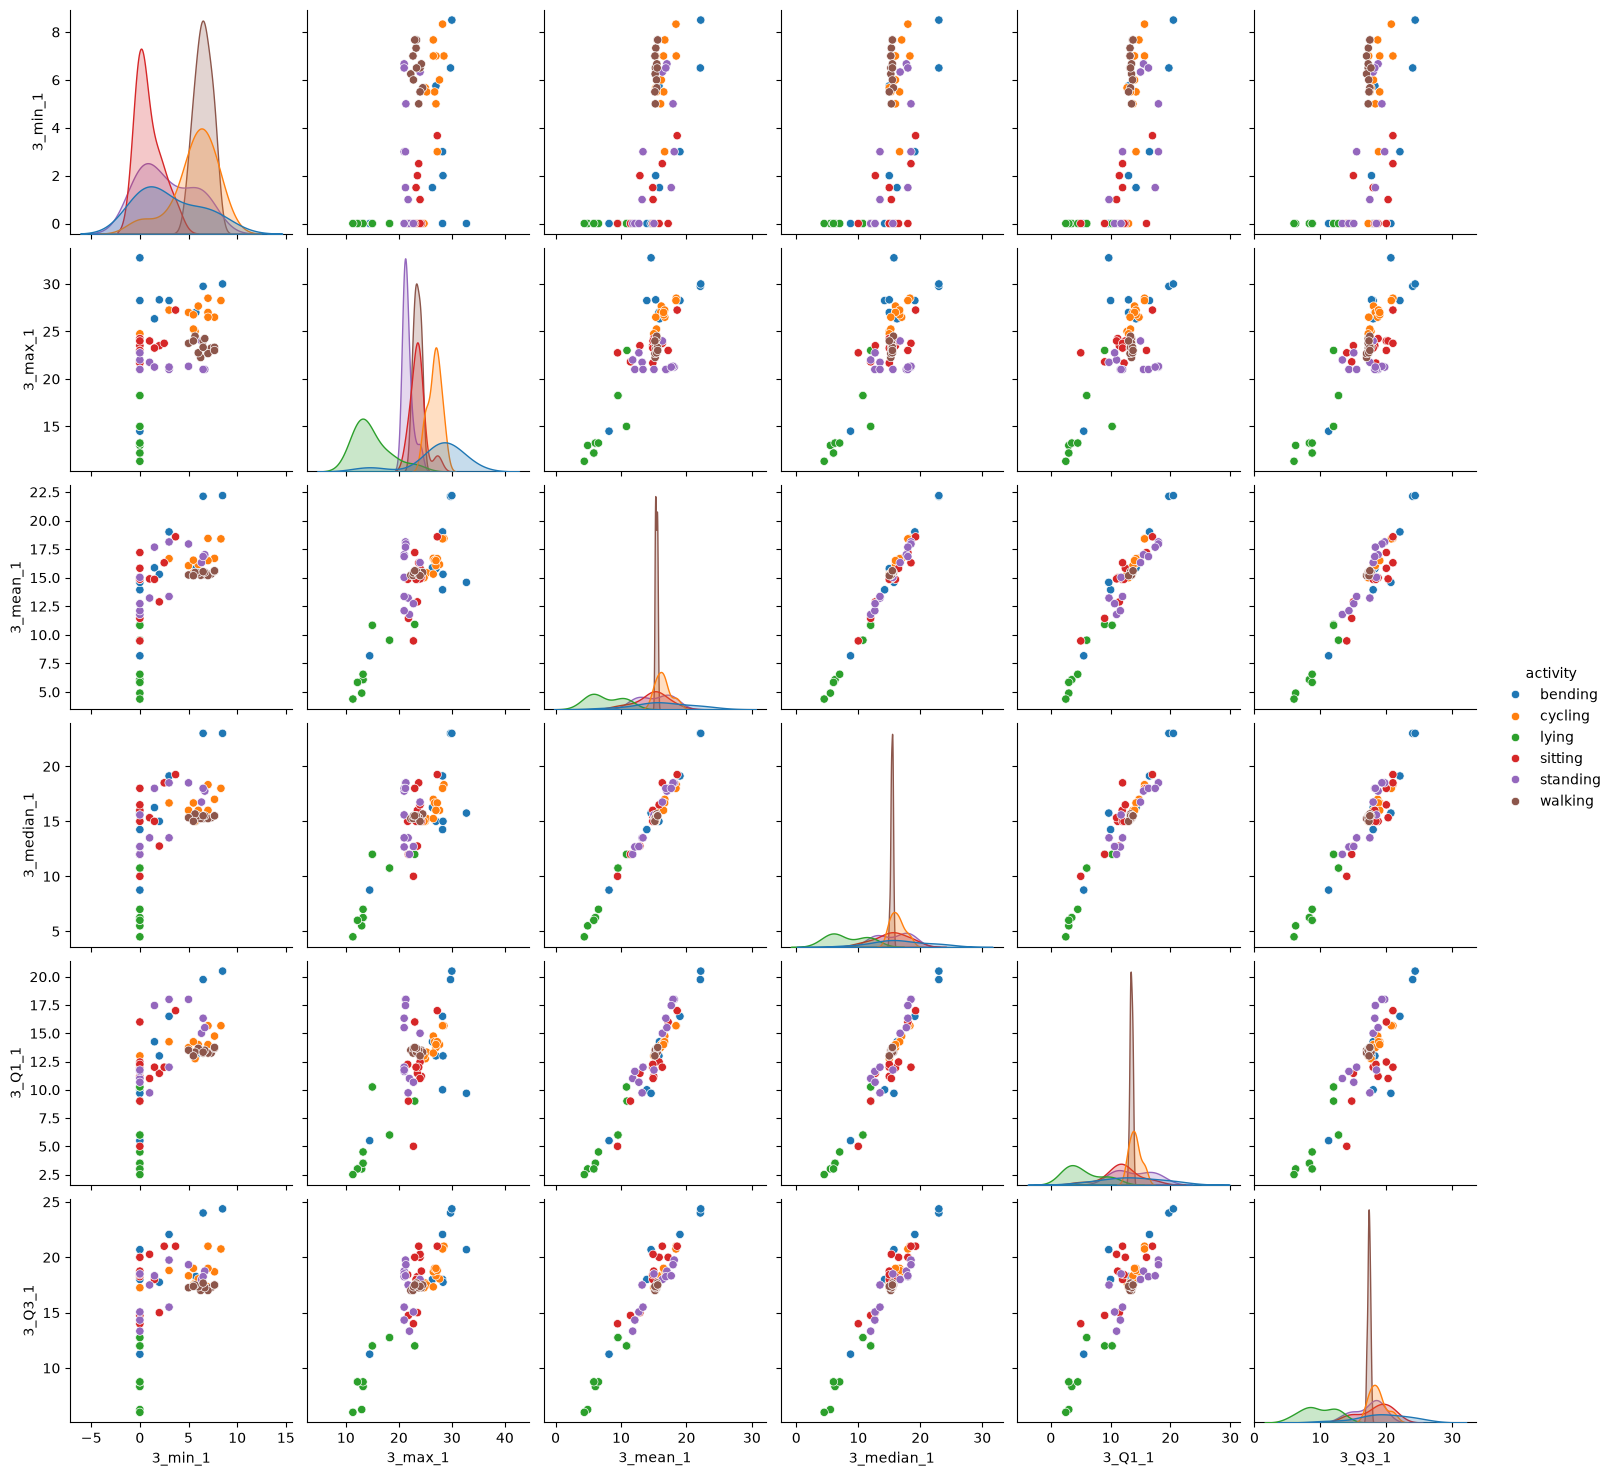

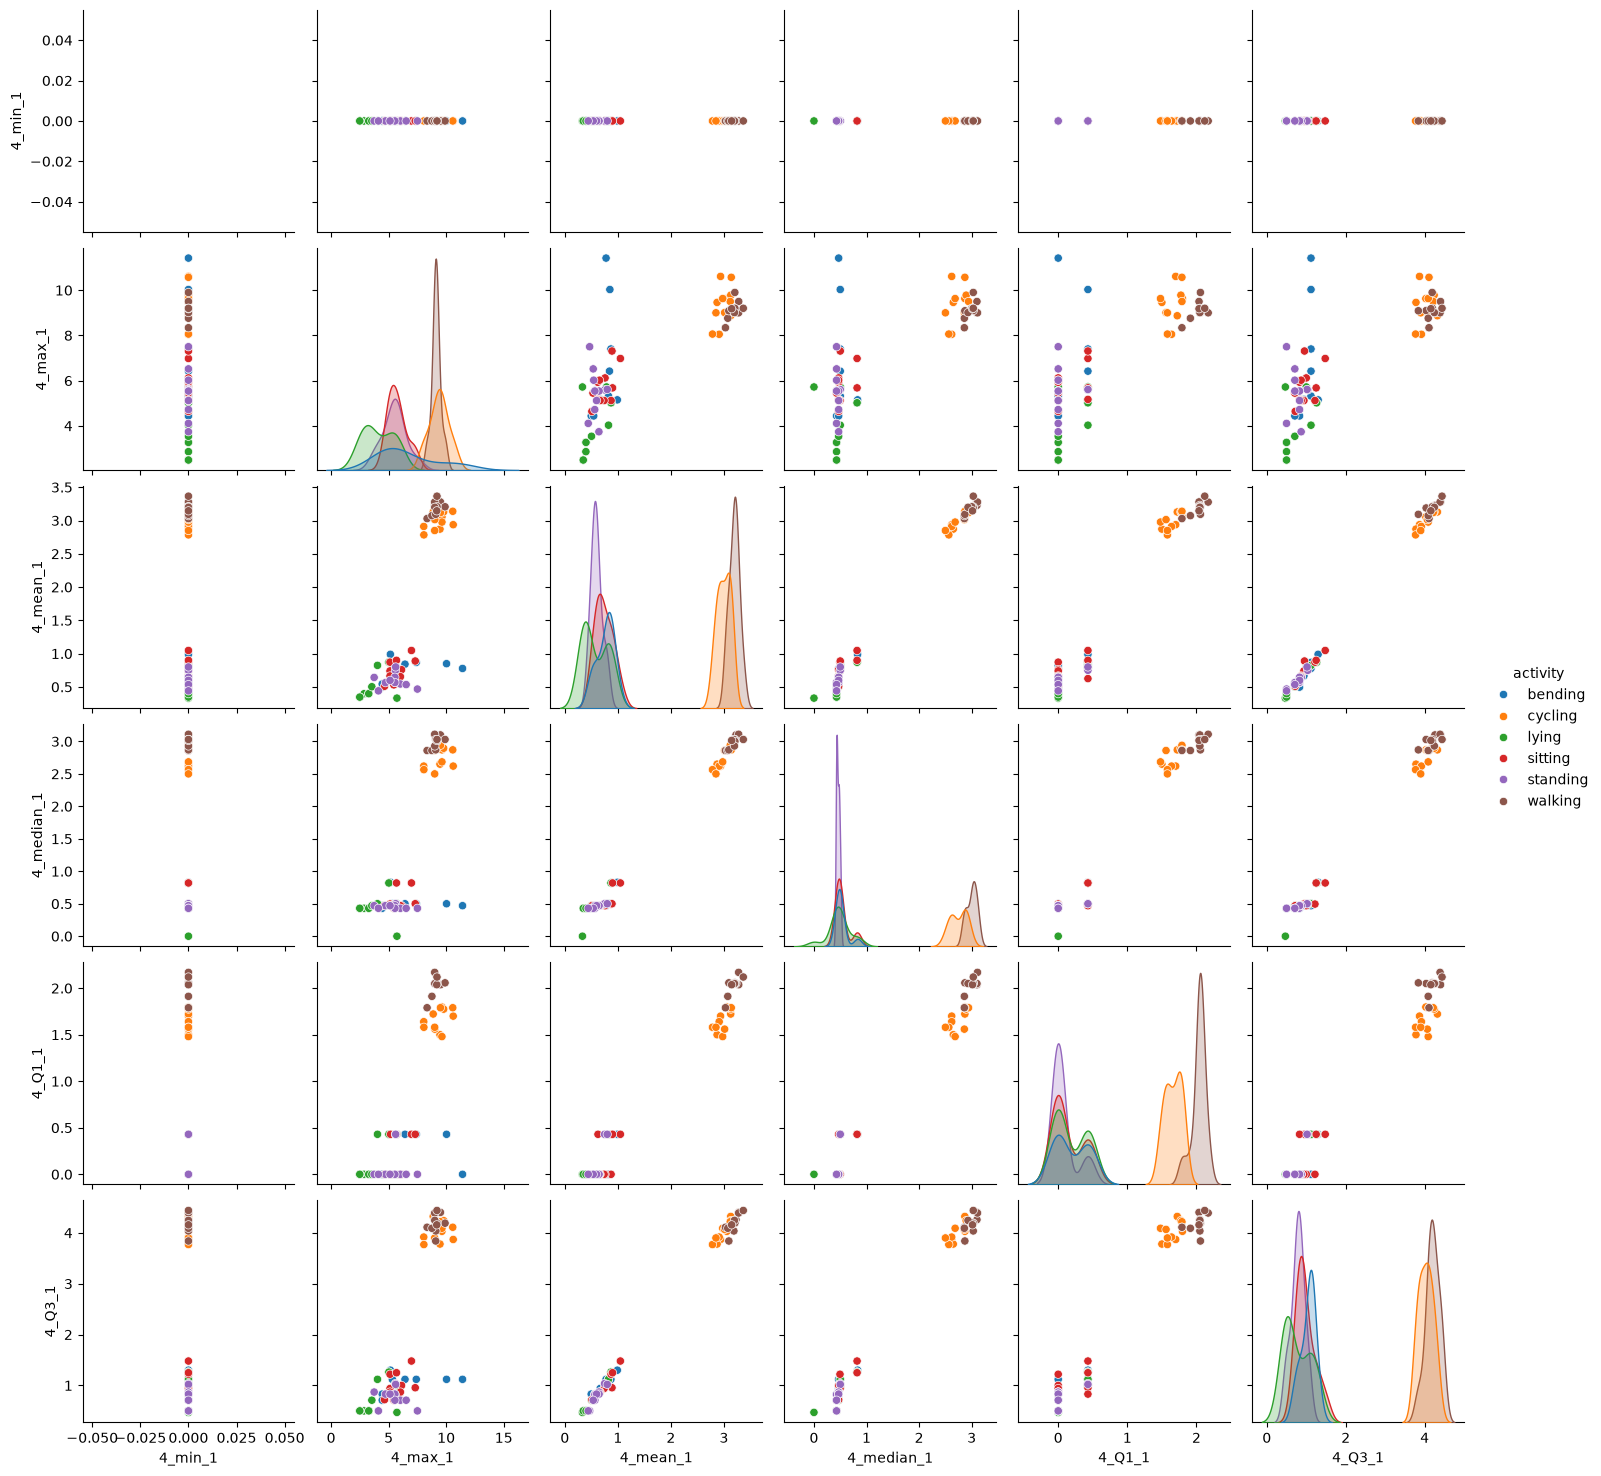

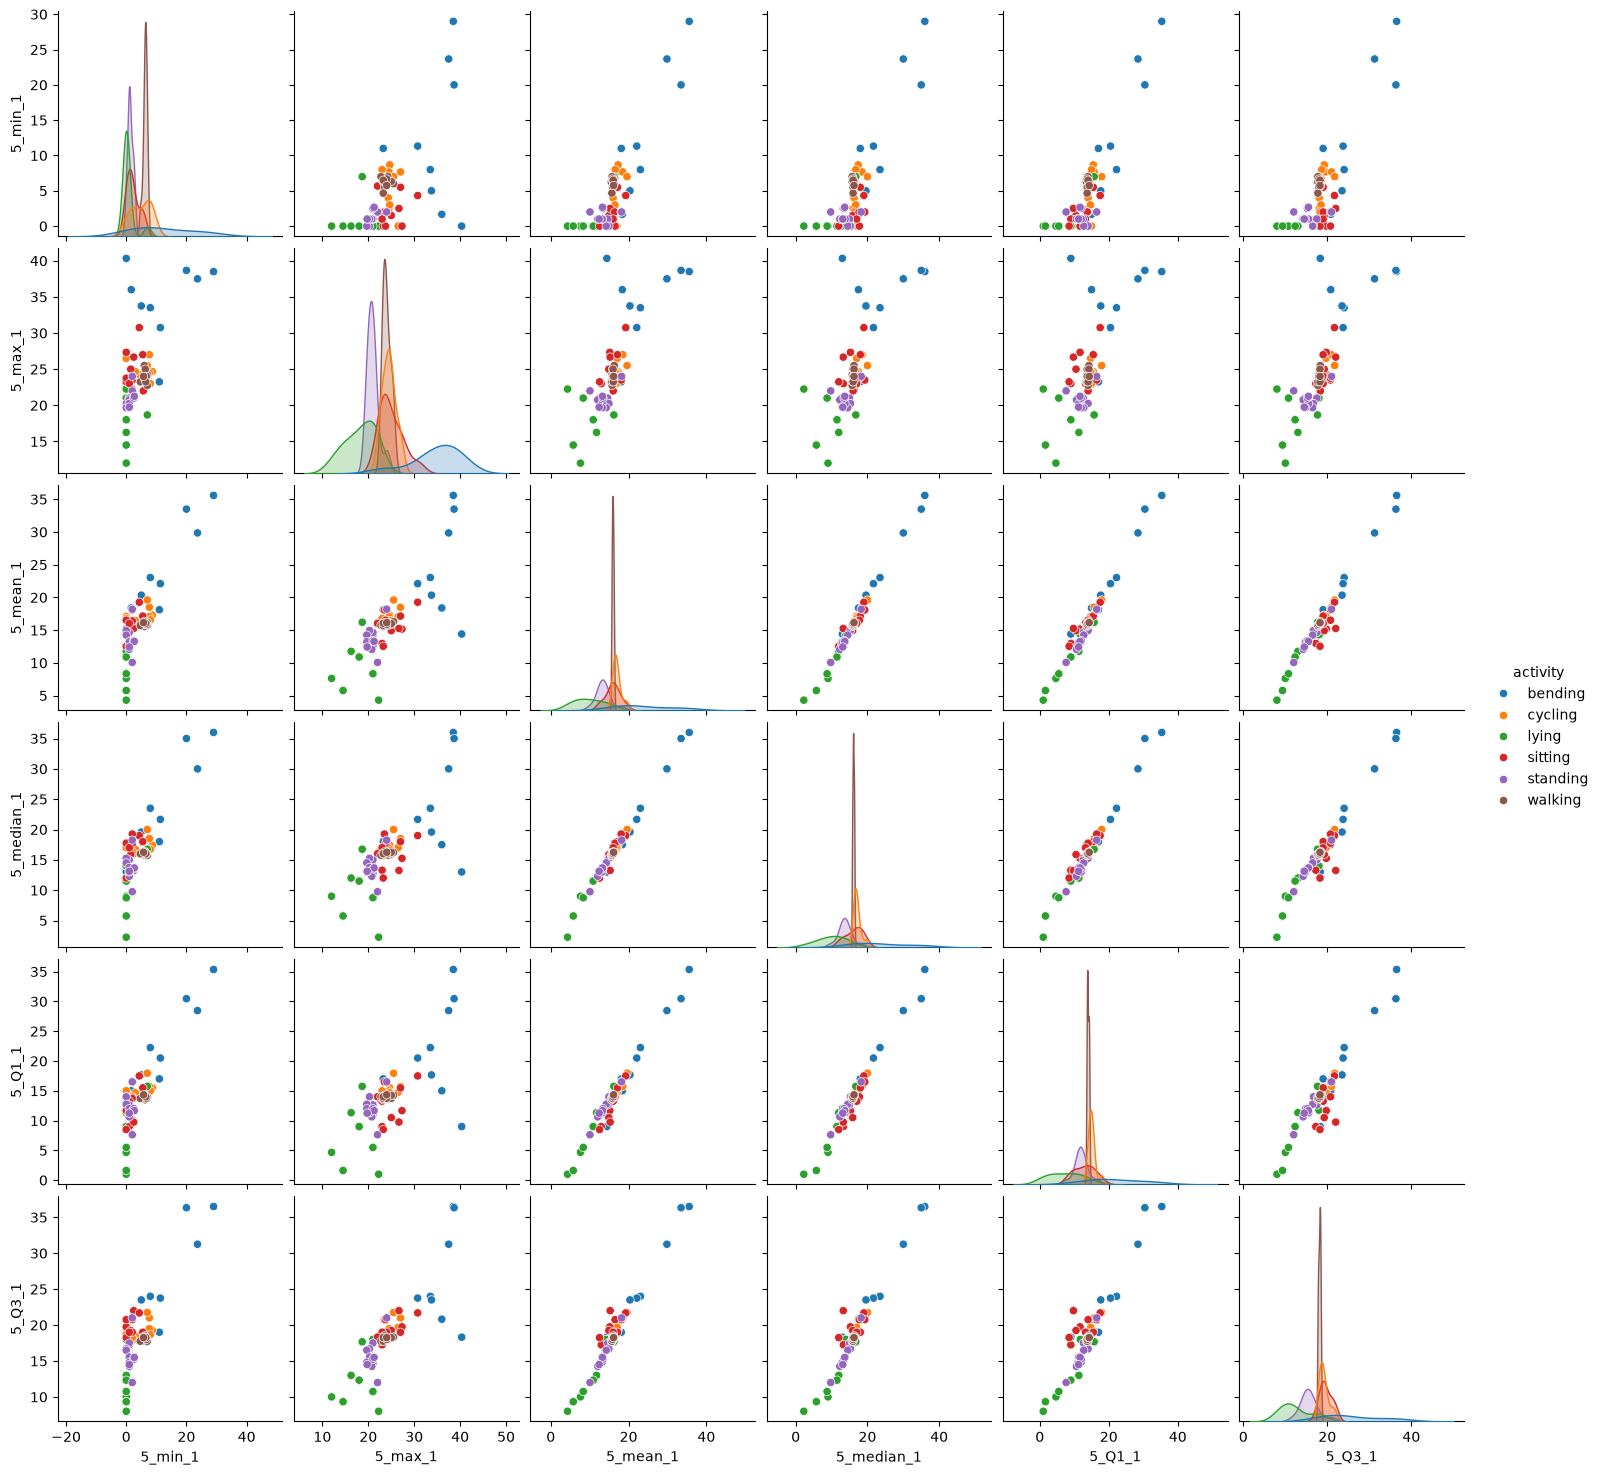

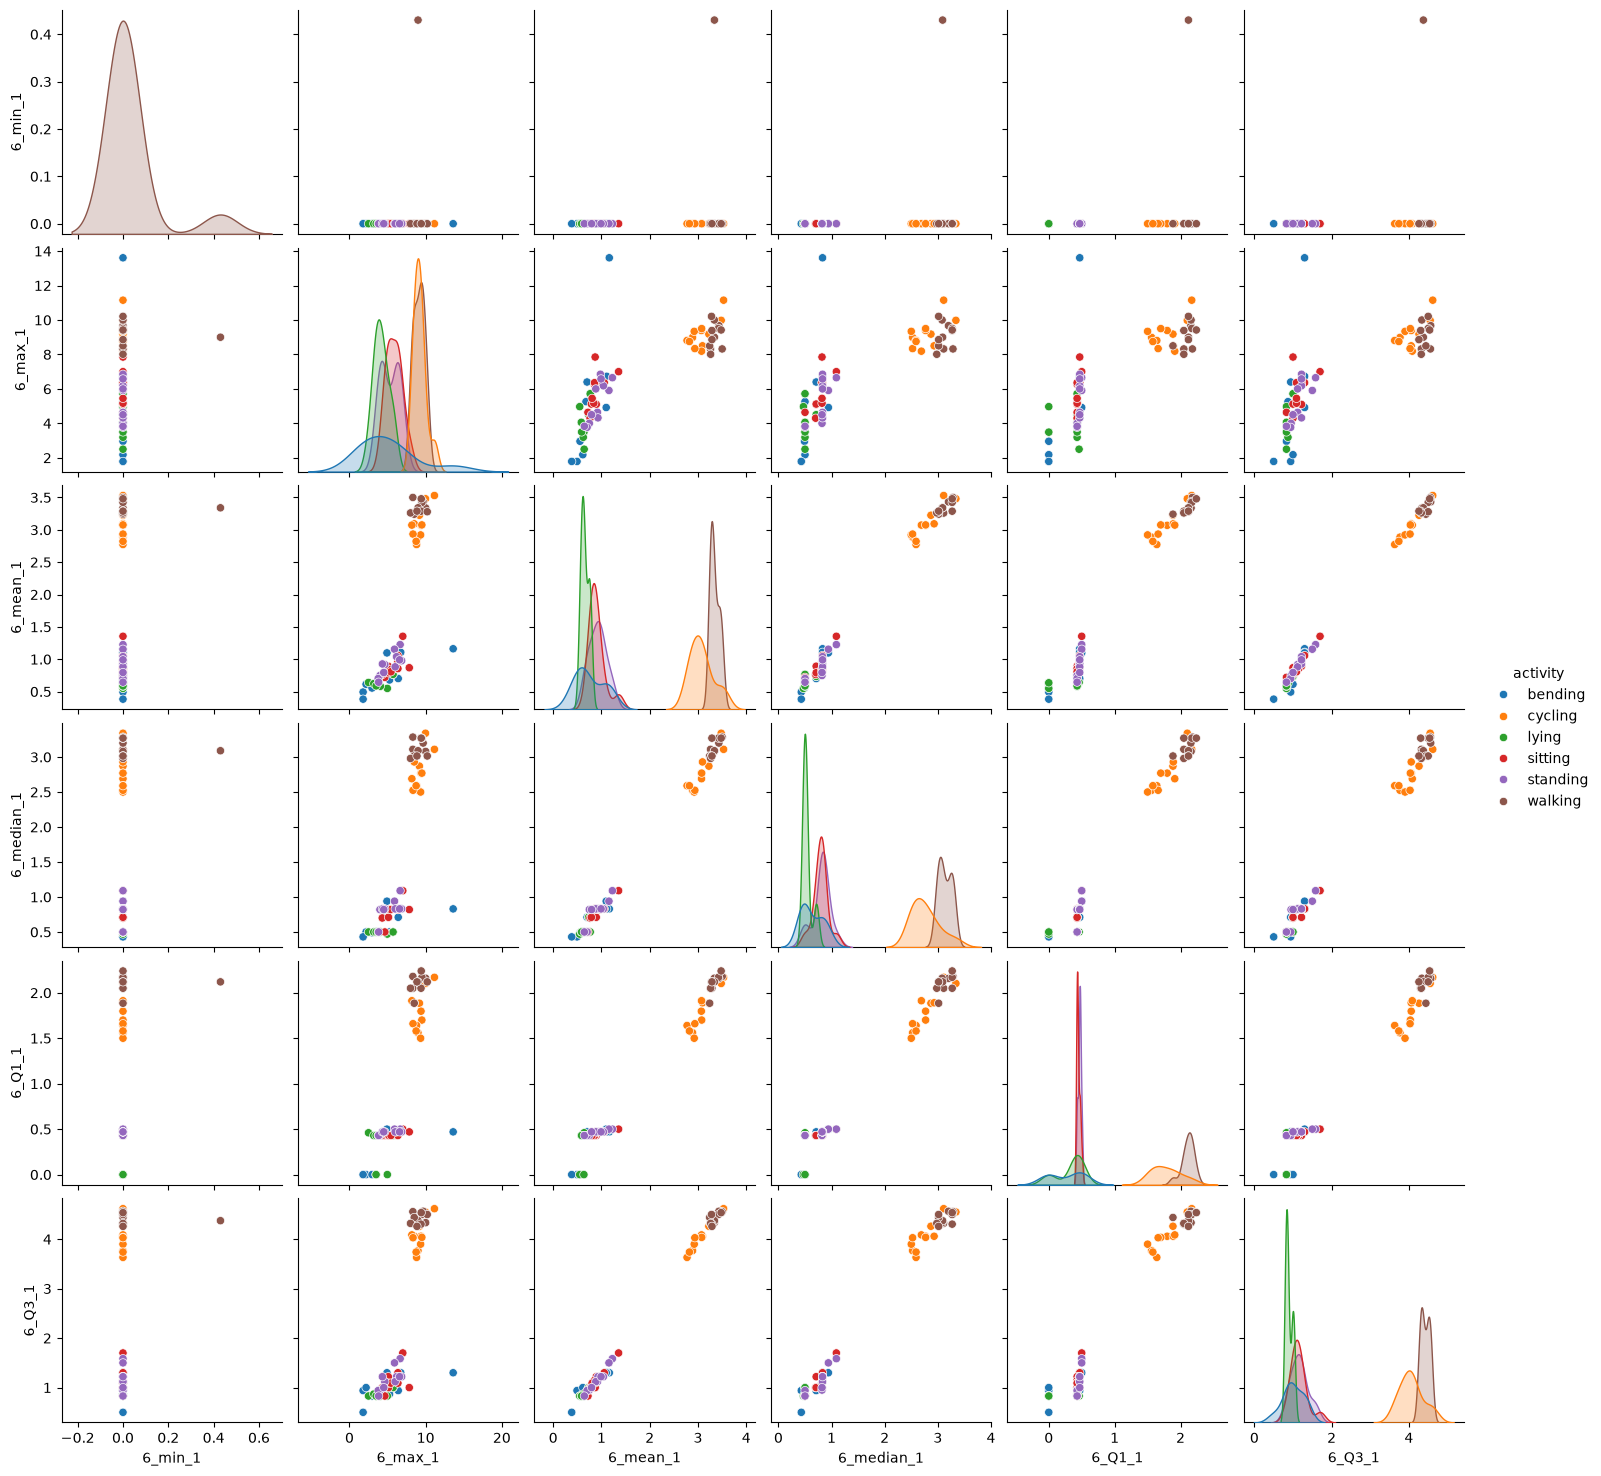

In [48]:
multiModel_labels = []
for k,g in my_instances:
    multiModel_labels.append(re.sub(r"\d+","",k[0]))

y_multi = np.array(multiModel_labels)

copy_df = X_for_l[1].copy()
copy_df["activity"] = y_multi

for c in cols:
    multi_cols = []
    for s in stats:
        multi_cols.append(str(c) + "_" + s + "_1")
    sns.pairplot(copy_df[multi_cols + ["activity"]],hue="activity")
    plt.show()

In [ ]:
#Cross validation


#### ii. Naive Bayes

#### ii. Comparison

## 3. ISLR 4.8.3

In [55]:
from IPython.display import Latex,display
print("So to answer this question, we have to start with the setup for the bayes equation which is:")
print("\n")
display(Latex(r"$$p_k(x) = P(Y = k \mid X = x) = \frac{\pi_k f_k(x)}{\sum_{l=1}^{K} \pi_l f_l(x)}$$"))

So to answer this question, we have to start with the setup for the bayes equation which is:




<IPython.core.display.Latex object>

In [59]:
print("Which then to prove that the classifier is nonlinear, we have to dissect the numerator portion of the bayes theorem equation because the denominator does not have much change depending on classes. So after taking the log of the bayes theorm you get this equation: ")
print("\n")
display(Latex(r"$$\log(\pi_k) - \log(\sigma_k) - \frac{(x-\mu_k)^2}{2\sigma_k^2}$$"))

Which then to prove that the classifier is nonlinear, we have to dissect the numerator portion of the bayes theorem equation because the denominator does not have much change depending on classes. So after taking the log of the bayes theorm you get this equation: 




<IPython.core.display.Latex object>

In [60]:
print("The next step in proving nonlinearity of this theorem would be to then expand the squares in this formula to group by powers of x if any. The equation from the previous step then becomes: ")
print("\n")
display(Latex(r"$$\delta_k(x) = -\frac{1}{2\sigma_k^2}x^2 + \frac{\mu_k}{\sigma_k^2}x + \left(\log\pi_k - \log\sigma_k - \frac{\mu_k^2}{2\sigma_k^2}\right)$$"))

The next step in proving nonlinearity of this theorem would be to then expand the squares in this formula to group by powers of x if any. The equation from the previous step then becomes: 




<IPython.core.display.Latex object>

Since we can drop of the coefficients, when evaluating the powers of x that was grouped in the last step, it can be seen that the bayes classifier is indeed non-linear and is quadratic. It is quadratic due to the high degree of polynomials obtained through the proving of the bayes classifier equation.

## 4. ISLR 4.8.7

The setup:\
Yes(div): X_1 = 10, var_1 = 0.8\
No(div): X_0 = 0, var_o = 0.2\
Combined var: var^2 = 36 -> var = 6\
num of observations: 4


In [61]:
print("The setup for solving this probability problem, would be to use the bayes theorem. The equation of this theorem is:")
print("\n")
display(Latex(r"$$P(Y=\text{Yes}\mid X=4) = \frac{\pi_1 f_1(4)}{\pi_1 f_1(4) + \pi_0 f_0(4)}$$"))


The setup for solving this probability problem, would be to use the bayes theorem. The equation of this theorem is:




<IPython.core.display.Latex object>

In [68]:
print("After setting up the initial equation, the density function for normal random variables has to be in order to figure out the probability. The equation for the density function:")
print("\n")
display(Latex(r"$$f(x)=\frac{1}{\sqrt{2\pi\sigma^2}}\,e^{-\frac{(x-\mu)^2}{2\sigma^2}}$$"))

After setting up the initial equation, the density function for normal random variables has to be in order to figure out the probability. The equation for the density function:




<IPython.core.display.Latex object>

Since the constants of 1/2 * pi * sigma^2 can be canceled out due it being present in both the numerator and denominator of the bayes equation.\
The next step would then be to plug in all the information given in the probelm and solve the equation.\
The setup to solve the equation would look like this:

In [69]:
display(Latex(r"$$P(\text{Yes}\mid X=4)=\frac{0.8\,e^{-\frac{(4-10)^2}{72}}}{0.8\,e^{-\frac{(4-10)^2}{72}}+0.2\,e^{-\frac{(4-0)^2}{72}}}$$"))

<IPython.core.display.Latex object>

Which then simplifies down to a fraction of 0.485 / 0.645, which = 75.2%

## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9